# AWS Core Services for AI Engineers: Identity, Networking, Compute, Data, Integration, Security and Delivery

> **Who is this for:** you can train a model or call an LLM API, and now you have to put it on AWS. The overview notebook [AWS for AI/ML](01_aws_for_ai.ipynb) named the big services. This notebook goes one level deeper into the **core** services that every AI system on AWS stands on.
>
> **What you will learn:**
> - **Accounts and identity:** root user, IAM users, roles and policies, how AWS decides "allow" or "deny" (explicit deny, permissions boundaries, SCPs and RCPs), Organizations and Control Tower, IAM Identity Center, Access Analyzer. You will run a small **IAM policy evaluator**.
> - **The shared responsibility model:** what AWS secures and what you secure.
> - **Networking:** VPC, CIDR, public and private subnets, route tables, internet and NAT gateways, security groups vs network ACLs, VPC endpoints and PrivateLink, peering and Transit Gateway. You will run a **CIDR / subnet planner**, a **route lookup** and a **firewall simulator**.
> - **Compute:** EC2 (including GPU families), Auto Scaling groups, load balancers, Lambda (including durable functions and Lambda Managed Instances), ECS and Fargate, ECS Express Mode (the App Runner successor), EKS (Auto Mode, Pod Identity, IRSA), AWS Batch.
> - **Storage and data:** S3 classes and lifecycle, S3 Vectors, EBS / EFS / FSx for Lustre, RDS and Aurora, DynamoDB key design, ElastiCache / MemoryDB / Valkey.
> - **Integration:** SQS, SNS, EventBridge (rules, Scheduler, Pipes), Step Functions, MWAA (managed Airflow).
> - **Observability and governance:** CloudWatch (metrics, logs, Logs Insights, Container Insights), CloudTrail, Config.
> - **Infrastructure as code:** CloudFormation, CDK, SAM. **Edge and DNS:** Route 53, CloudFront, Lambda@Edge.
> - **Security services:** Cognito, KMS, Secrets Manager, GuardDuty, Security Hub, Inspector, WAF and Shield. **CI/CD:** CodePipeline, CodeBuild, CodeDeploy, CodeArtifact.
> - A **reference architecture for an AI API on AWS** and a **Well-Architected checklist** you can score.
>
> **Prerequisites:** [AWS for AI/ML](01_aws_for_ai.ipynb) (the overview), [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb) (IP addresses, ports, TLS). Helpful: [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb), [Docker basics](../17_Docker/01_docker_basics.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb).
>
> **Time needed:** about 3 hours to read. The code runs in a few seconds.
>
> **Runs on:** CPU, **no AWS account, no API key, no internet**. Every AWS CLI, boto3, CloudFormation or CDK snippet is shown as text (or in a guarded cell that prints `skipped: needs ...`). The runnable parts are small simulations written in plain Python.

**Note on dates.** AWS releases new features every week. Service names and features below are written **as of late 2026**. When a service was renamed or closed to new customers, this notebook says so once. Check the official docs (linked in "Further reading") before you build something real. Prices are left out on purpose. Any number marked "illustrative" is made up for teaching.

**What comes next.** The AI-specific services (SageMaker AI, Bedrock, AgentCore, Trainium, and so on) are in the companion notebook [AWS AI services: SageMaker AI, Bedrock and AgentCore](07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb). Cost planning is in [Cloud cost optimization](04_cloud_cost_optimization.ipynb) and [Cloud ML architecture and cost planning](05_industry_cloud_ml_architecture_and_cost_planning.ipynb).

## Table of contents

0. Setup
1. The big picture: regions, AZs, accounts, and the shared responsibility model
2. Identity and access: root, IAM, policies, and the policy evaluator
3. Multi-account governance: Organizations, SCPs, RCPs, Control Tower, Identity Center, Access Analyzer
4. Networking: VPC, subnets, routing, firewalls, endpoints
5. Compute: EC2, Auto Scaling, load balancers, Lambda, containers, EKS, Batch
6. Storage and databases
7. Integration: queues, events, workflows
8. Observability and governance: CloudWatch, CloudTrail, Config
9. Infrastructure as code: CloudFormation, CDK, SAM
10. Edge and DNS: Route 53, CloudFront, Lambda@Edge
11. Security services: Cognito, KMS, Secrets Manager, GuardDuty, Security Hub, Inspector, WAF, Shield
12. CI/CD on AWS: CodePipeline, CodeBuild, CodeDeploy, CodeArtifact
13. Reference architecture: an AI API on AWS
14. Well-Architected checklist (runnable scorer)
15. Service map: AWS vs Azure vs GCP
16. How to try it for real (free tier and local tools)
17. Certification topic map
18. Recap / cheat sheet
19. Interview questions
20. Further reading

## 0. Setup

We only use the standard library plus numpy, pandas and matplotlib. A fixed random seed keeps every simulation the same each time you run it.

In [1]:
import ipaddress, json, fnmatch, re, math, random, hashlib, os, shutil, textwrap
from collections import defaultdict, deque
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Is the real AWS tooling here? We never call it, we only report it.
HAS_AWS_CLI = shutil.which("aws") is not None
HAS_CREDS = bool(os.environ.get("AWS_ACCESS_KEY_ID") or os.environ.get("AWS_PROFILE"))
print("aws CLI found:", HAS_AWS_CLI, "| credentials in env:", HAS_CREDS)
print("This notebook never calls AWS. Everything below is a local simulation.")

aws CLI found: True | credentials in env: False
This notebook never calls AWS. Everything below is a local simulation.


## 1. The big picture: regions, AZs, accounts, and the shared responsibility model

### 1.1 Regions, Availability Zones and edge locations

**What it is.** A **Region** is a geographic area (for example `us-east-1` in North Virginia or `eu-west-1` in Ireland). Each Region has several **Availability Zones (AZs)**. An AZ is one or more separate data centres with their own power and network. **Edge locations** are smaller sites close to users, used by CloudFront and Route 53. **Local Zones**, **Wavelength** and **Outposts** push AWS closer to users or into your own building.

**Simple analogy.** A Region is a city. AZs are separate neighbourhoods in that city with their own power station. If one neighbourhood has a blackout, the others keep working.

**How it works.**
- Most services are **regional**: an S3 bucket, a Lambda function and a VPC all live in one Region.
- A few services are **global**: IAM, Route 53, CloudFront, Organizations.
- High availability = run copies of your service in **at least two AZs** of one Region. Disaster recovery = also keep a copy in **another Region**.

**When to care.** Pick a Region close to your users, where the AI models and GPU instances you need are offered, and that matches your data-residency rules (some data must stay in one country).

### 1.2 Accounts

**What it is.** An **AWS account** is a container for resources and a billing boundary. Big companies use **many accounts** (dev, staging, prod, security, logging), grouped with AWS Organizations (section 3).

**Analogy.** An account is a flat in a building. Each flat has its own key and its own electricity meter.

### 1.3 The shared responsibility model

**What it is.** AWS secures the **cloud itself** ("security **of** the cloud"). You secure **what you put in the cloud** ("security **in** the cloud"). The line moves depending on how managed a service is.

**Analogy.** Renting a flat: the landlord fixes the building, the lifts and the main door lock. You lock your own door, choose who gets a key, and do not leave the windows open.

| Layer | EC2 (you run the server) | Lambda / Fargate (serverless) | Bedrock / S3 (fully managed) |
|---|---|---|---|
| Physical data centres, hardware, global network | AWS | AWS | AWS |
| Hypervisor, host OS | AWS | AWS | AWS |
| Guest OS patches | **You** | AWS | AWS |
| Runtime / container image | **You** | **You** (your code and dependencies) | AWS |
| Network rules (security groups, NACLs) | **You** | **You** (if in a VPC) | mostly AWS (you set endpoint/bucket policies) |
| IAM: who can do what | **You** | **You** | **You** |
| Your data: encryption choices, classification, backups | **You** | **You** | **You** |
| Prompts, model outputs, guardrails, responsible-AI choices | **You** | **You** | **You** |

The rows at the bottom are **always yours**: identity, data and how you use AI. That is why IAM and encryption appear in every AWS exam.

In [2]:
# A tiny helper: "who is responsible?" for a few common tasks.
RESPONSIBILITY = {
    # task                                  : {service_type: owner}
    "patch the guest operating system":       {"EC2": "you", "Lambda": "AWS", "Bedrock": "AWS"},
    "physical security of the data centre":   {"EC2": "AWS", "Lambda": "AWS", "Bedrock": "AWS"},
    "write least-privilege IAM policies":     {"EC2": "you", "Lambda": "you", "Bedrock": "you"},
    "encrypt sensitive training data":        {"EC2": "you", "Lambda": "you", "Bedrock": "you"},
    "scale the servers behind the API":       {"EC2": "you", "Lambda": "AWS", "Bedrock": "AWS"},
    "block prompt-injection in your app":     {"EC2": "you", "Lambda": "you", "Bedrock": "you"},
}
print(pd.DataFrame(RESPONSIBILITY).T)

                                      EC2 Lambda Bedrock
patch the guest operating system      you    AWS     AWS
physical security of the data centre  AWS    AWS     AWS
write least-privilege IAM policies    you    you     you
encrypt sensitive training data       you    you     you
scale the servers behind the API      you    AWS     AWS
block prompt-injection in your app    you    you     you


## 2. Identity and access: root, IAM, policies, and the policy evaluator

### 2.1 The root user

**What it is.** The email address and password that created the account. The root user can do **everything**, including closing the account. IAM policies cannot limit it (only SCPs can, in a member account of an Organization).

**Rule of thumb.** Turn on MFA (multi-factor authentication) for root, delete root access keys, and **never** use root for daily work.

### 2.2 IAM users, groups, roles

| Thing | What it is (one sentence) | Credentials | Use it for |
|---|---|---|---|
| **IAM user** | A long-lived identity for one person or app inside one account. | Password and/or **long-lived** access keys | Legacy, break-glass. Prefer Identity Center for people and roles for apps. |
| **IAM group** | A set of users that share policies. | none | Attaching the same policy to many users. |
| **IAM role** | An identity that someone or something **assumes** for a while. | **Temporary** credentials from STS | EC2 instance profiles, Lambda execution roles, ECS task roles, cross-account access, people via SSO. |
| **Service-linked role** | A role owned by an AWS service so it can act for you. | temporary | Created by services like ECS, Auto Scaling. |

**Analogy.** A user is a staff ID card with your photo. A role is a visitor badge you pick up at reception, which expires at the end of the day.

**How a role works.**
1. The role has a **trust policy**: who is allowed to assume it (for example `lambda.amazonaws.com`, or another account).
2. The caller calls **STS `AssumeRole`** (AWS does this for you on EC2 / Lambda / ECS).
3. STS returns **temporary credentials** (access key, secret, session token) that expire (default 1 hour).
4. The role's **permission policies** decide what those credentials can do.

### 2.3 Policies: the JSON language

A policy is a JSON document with one or more **statements**. Each statement has:
- `Effect`: `Allow` or `Deny`
- `Action`: API actions, like `s3:GetObject` or `bedrock:InvokeModel` (wildcards allowed: `s3:Get*`)
- `Resource`: ARNs (Amazon Resource Names) like `arn:aws:s3:::my-bucket/*`
- `Condition` (optional): extra checks, like "only from this VPC endpoint" or "only if MFA was used"
- `Principal`: only in **resource-based** policies (bucket policies, KMS key policies, role trust policies): who the statement is about.

**Policy types you must know**

| Policy type | Attached to | Grants? | Limits? |
|---|---|---|---|
| Identity-based (managed or inline) | user, group, role | yes | - |
| Resource-based | resource (S3 bucket, KMS key, SQS queue, Lambda) | yes | - |
| **Permissions boundary** | user or role | **no** | yes, a ceiling |
| **Session policy** | passed when assuming a role | **no** | yes, a ceiling |
| **SCP** (service control policy) | Organization root, OU, account | **no** | yes, ceiling for **principals** in the account |
| **RCP** (resource control policy) | Organization root, OU, account | **no** | yes, ceiling for **resources** in the account |

### 2.4 How AWS decides: policy evaluation logic

From the official IAM docs (single-account request, simplified):

```mermaid
flowchart TD
    A[Request arrives. Default = implicit DENY] --> B{Any explicit Deny in ANY policy?}
    B -- yes --> D[DENY]
    B -- no --> C{RCPs allow? if RCPs used}
    C -- no --> D
    C -- yes --> E{SCPs allow? if in an Organization}
    E -- no --> D
    E -- yes --> F{Resource-based policy allows this principal?}
    F -- yes, grants to the user or session directly --> Z[ALLOW]
    F -- no / grants to role ARN --> G{Identity-based policy allows?}
    G -- no --> D
    G -- yes --> H{Permissions boundary allows? if set}
    H -- no --> D
    H -- yes --> I{Session policy allows? if passed}
    I -- no --> D
    I -- yes --> Z
```

Three rules to remember:
1. **Everything starts as an implicit deny.**
2. **One explicit deny anywhere wins.** No allow can beat it.
3. **Ceilings** (SCP, RCP, boundary, session policy) never grant anything. They only cut down what the grant policies allow. Effective permissions are roughly *(identity allows OR resource allows) AND every ceiling allows AND no explicit deny*.

Cross-account requests are stricter: **both** sides must allow (the identity policy in account A **and** the resource policy in account B).

### 2.5 Runnable: a toy IAM policy evaluator

This evaluator follows the order above for **same-account** requests. It supports `Allow` / `Deny`, wildcards in `Action` and `Resource`, `NotAction`, and a few condition operators (`StringEquals`, `StringLike`, `Bool`, `IpAddress`). It is a teaching toy: real IAM has many more condition keys, variables like `${aws:username}`, and service-specific rules. To test real policies, use the **IAM policy simulator** or **IAM Access Analyzer policy validation** (section 3).

In [3]:
def _as_list(x):
    """IAM lets you write a single string or a list. Always return a list."""
    if x is None:
        return []
    return x if isinstance(x, list) else [x]

def _match(pattern, value):
    """IAM-style wildcard match (* and ?), case-insensitive for actions."""
    return fnmatch.fnmatchcase(value.lower(), pattern.lower())

def _condition_ok(cond, ctx):
    """Check a Condition block against the request context. All operators must pass (AND)."""
    for op, checks in (cond or {}).items():
        for key, expected in checks.items():
            actual = ctx.get(key)
            expected = _as_list(expected)
            if op == "StringEquals":
                ok = actual is not None and str(actual) in [str(e) for e in expected]
            elif op == "StringLike":
                ok = actual is not None and any(fnmatch.fnmatchcase(str(actual), e) for e in expected)
            elif op == "Bool":
                ok = actual is not None and str(actual).lower() in [str(e).lower() for e in expected]
            elif op == "IpAddress":
                ok = actual is not None and any(ipaddress.ip_address(actual) in ipaddress.ip_network(e) for e in expected)
            else:
                raise ValueError(f"operator {op} not supported by this toy")
            if not ok:
                return False
    return True

def statement_applies(stmt, action, resource, ctx, principal=None):
    """Does this one statement match the request?"""
    if "Principal" in stmt and principal is not None:          # resource-based policies name a principal
        allowed = _as_list(stmt["Principal"].get("AWS")) if isinstance(stmt["Principal"], dict) else _as_list(stmt["Principal"])
        if not any(p == "*" or p == principal for p in allowed):
            return False
    if "Action" in stmt and not any(_match(a, action) for a in _as_list(stmt["Action"])):
        return False
    if "NotAction" in stmt and any(_match(a, action) for a in _as_list(stmt["NotAction"])):
        return False
    if not any(_match(r, resource) for r in _as_list(stmt.get("Resource", "*"))):
        return False
    return _condition_ok(stmt.get("Condition"), ctx)

def find(policies, effect, action, resource, ctx, principal=None):
    """Return the first matching statement with this Effect (or None)."""
    for pol in policies:
        for st in _as_list(pol.get("Statement")):
            if st["Effect"] == effect and statement_applies(st, action, resource, ctx, principal):
                return st.get("Sid", "(no Sid)")
    return None

In [4]:
def evaluate(request, identity=(), resource_policies=(), boundary=None, session=None, scps=None, rcps=None):
    """Toy version of the official single-account evaluation order.
    Ceiling policies set to None mean 'not used'. Returns (decision, reason)."""
    a, r, ctx, who = request["action"], request["resource"], request.get("context", {}), request["principal"]
    everything = list(identity) + list(resource_policies) + [p for p in (boundary, session) if p] \
                 + list(scps or []) + list(rcps or [])
    # 1) Explicit deny anywhere wins.
    sid = find(everything, "Deny", a, r, ctx, who)
    if sid: return "DENY", f"explicit deny ({sid})"
    # 2) RCPs and 3) SCPs: ceilings. If used, they must contain an Allow.
    if rcps is not None and not find(rcps, "Allow", a, r, ctx):
        return "DENY", "no Allow in resource control policies (RCP)"
    if scps is not None and not find(scps, "Allow", a, r, ctx):
        return "DENY", "no Allow in service control policies (SCP)"
    # 4) Resource-based policy that names THIS principal (user or session) can grant on its own.
    if find(resource_policies, "Allow", a, r, ctx, who) and request.get("principal_type") in ("user", "session"):
        return "ALLOW", "resource-based policy grants directly to this principal"
    resource_allows = find(resource_policies, "Allow", a, r, ctx, who) is not None
    # 5) Identity-based policies (or a resource policy that names the role ARN).
    if not (find(identity, "Allow", a, r, ctx) or resource_allows):
        return "DENY", "implicit deny: nothing allows it"
    # 6) Permissions boundary and 7) session policy: ceilings.
    if boundary is not None and not find([boundary], "Allow", a, r, ctx):
        return "DENY", "implicit deny: outside the permissions boundary"
    if session is not None and not find([session], "Allow", a, r, ctx):
        return "DENY", "implicit deny: outside the session policy"
    return "ALLOW", "allowed by identity/resource policy and every ceiling"

In [5]:
# Example policies for an ML engineer role that calls Bedrock and reads training data.
ml_role_policy = {"Statement": [
    {"Sid": "ReadTrainingData", "Effect": "Allow", "Action": ["s3:GetObject", "s3:ListBucket"],
     "Resource": ["arn:aws:s3:::ml-data", "arn:aws:s3:::ml-data/*"]},
    {"Sid": "CallModels", "Effect": "Allow", "Action": "bedrock:InvokeModel*", "Resource": "*"},
    {"Sid": "NoDeleteEver", "Effect": "Deny", "Action": "s3:Delete*", "Resource": "*"},
]}
boundary = {"Statement": [  # the platform team says: this role may only ever touch S3 and Bedrock
    {"Effect": "Allow", "Action": ["s3:*", "bedrock:*"], "Resource": "*"}]}
scp_region_lock = {"Statement": [  # organisation-wide rule: only two Regions
    {"Sid": "AllowAll", "Effect": "Allow", "Action": "*", "Resource": "*"},
    {"Sid": "DenyOtherRegions", "Effect": "Deny", "NotAction": ["iam:*", "sts:*"], "Resource": "*",
     "Condition": {"StringLike": {"aws:RequestedRegion": "ap-*"}}}]}
bucket_policy = {"Statement": [  # the bucket only accepts reads through our VPC endpoint
    {"Sid": "DenyOutsideVpce", "Effect": "Deny", "Principal": "*", "Action": "s3:GetObject",
     "Resource": "arn:aws:s3:::ml-data/*",
     "Condition": {"StringLike": {"aws:SourceVpce": "vpce-other*"}}}]}

ROLE = "arn:aws:iam::111122223333:role/ml-engineer"
tests = [
    ("read data via our endpoint", "s3:GetObject", "arn:aws:s3:::ml-data/train.csv", {"aws:RequestedRegion": "us-east-1", "aws:SourceVpce": "vpce-ours1"}),
    ("read data via a foreign endpoint", "s3:GetObject", "arn:aws:s3:::ml-data/train.csv", {"aws:RequestedRegion": "us-east-1", "aws:SourceVpce": "vpce-other9"}),
    ("delete a file", "s3:DeleteObject", "arn:aws:s3:::ml-data/train.csv", {"aws:RequestedRegion": "us-east-1"}),
    ("call a model in us-east-1", "bedrock:InvokeModel", "arn:aws:bedrock:us-east-1::foundation-model/x", {"aws:RequestedRegion": "us-east-1"}),
    ("call a model in ap-south-1", "bedrock:InvokeModel", "arn:aws:bedrock:ap-south-1::foundation-model/x", {"aws:RequestedRegion": "ap-south-1"}),
    ("start an EC2 GPU instance", "ec2:RunInstances", "*", {"aws:RequestedRegion": "us-east-1"}),
]
rows = []
for name, action, res, ctx in tests:
    req = {"principal": ROLE, "principal_type": "role", "action": action, "resource": res, "context": ctx}
    d, why = evaluate(req, identity=[ml_role_policy], resource_policies=[bucket_policy],
                      boundary=boundary, scps=[scp_region_lock])
    rows.append({"request": name, "action": action, "decision": d, "reason": why})
pd.DataFrame(rows)

,request,action,decision,reason
0,read data via our endpoint,s3:GetObject,ALLOW,allowed by identity/resource policy and every ceiling
1,read data via a foreign endpoint,s3:GetObject,DENY,explicit deny (DenyOutsideVpce)
2,delete a file,s3:DeleteObject,DENY,explicit deny (NoDeleteEver)
3,call a model in us-east-1,bedrock:InvokeModel,ALLOW,allowed by identity/resource policy and every ceiling
4,call a model in ap-south-1,bedrock:InvokeModel,DENY,explicit deny (DenyOtherRegions)
5,start an EC2 GPU instance,ec2:RunInstances,DENY,implicit deny: nothing allows it


**What to notice.**
- The delete is denied by an **explicit deny** even though nothing else mentions it.
- `ap-south-1` is blocked by the **SCP**, even though the role policy allows `bedrock:InvokeModel*` everywhere.
- `ec2:RunInstances` is an **implicit deny**: nothing allows it. Even if someone later adds it to the role policy, the **permissions boundary** would still block it. That is the point of boundaries: a team can create its own roles, but never beyond the boundary.

Try it: add `{"Effect": "Allow", "Action": "ec2:*", "Resource": "*"}` to `ml_role_policy` and re-run. The reason changes to "outside the permissions boundary".

### 2.6 Least privilege in practice
- Start from **AWS managed policies** for learning, then **tighten** to customer-managed policies that list exact actions and ARNs.
- Use **conditions**: `aws:SourceVpce`, `aws:PrincipalOrgID`, `aws:RequestedRegion`, `aws:MultiFactorAuthPresent`, tag-based conditions (ABAC, attribute-based access control: "allow if the resource tag `team` equals the caller's tag `team`").
- Give **each workload its own role** (one Lambda function, one role).
- Let **IAM Access Analyzer** generate a policy from real CloudTrail activity, and find unused permissions (next section).

## 3. Multi-account governance: Organizations, SCPs, RCPs, Control Tower, Identity Center, Access Analyzer

| Service | What it is (simple) | Analogy | When to use |
|---|---|---|---|
| **AWS Organizations** | Groups many accounts into a tree: root, **organizational units (OUs)**, accounts. One bill. | A company with departments. | As soon as you have more than one account. |
| **SCP** (service control policy) | A ceiling on what **principals** (users, roles) in an account can do. Root user of a member account is limited too. | Company rule: "no one in this department may buy servers abroad." | Region locks, "nobody can turn off CloudTrail", "only approved services". |
| **RCP** (resource control policy) | A ceiling on what can be done **to resources** (for example S3, KMS, SQS, STS, Secrets Manager) in the account, no matter who asks. | Rule on the building: "these doors only open for staff of our company." | Data perimeters: "our buckets can only be read by principals in our org". |
| **AWS Control Tower** | Sets up a well-designed multi-account **landing zone** for you: log archive and audit accounts, guardrails (controls), Account Factory. | A franchise starter kit. | New multi-account setups; do not hand-build what Control Tower gives you. |
| **IAM Identity Center** (formerly AWS SSO) | One login for people across all accounts. Connects to your identity provider (Okta, Entra ID, Google) and hands out **permission sets** (roles) per account. | One staff badge that opens the right doors in every building. | Always, for humans. Avoid IAM users for people. |
| **IAM Access Analyzer** | Finds resources shared outside your account or org (external access), finds **unused** roles/keys/permissions, **validates** policies, and can **generate** least-privilege policies from CloudTrail. | A security guard who walks around and lists every unlocked door. | Continuously, plus as a CI check on new policies. |
| **IAM policy simulator** | Console/API tool to test "would this principal be allowed to do X?" | The toy evaluator above, but real. | Debugging "AccessDenied". |

```mermaid
flowchart TD
    ROOT[Organization root<br/>SCP: deny leaving org, deny disabling CloudTrail] --> SEC[OU: Security<br/>log-archive, audit accounts]
    ROOT --> WL[OU: Workloads<br/>SCP: Region lock]
    WL --> DEV[OU: Dev<br/>ml-dev account]
    WL --> PROD[OU: Prod<br/>SCP: deny delete of KMS keys<br/>RCP: S3 only for org principals]
    PROD --> P1[ai-api-prod account]
    PROD --> P2[data-lake-prod account]
    IDC[IAM Identity Center<br/>permission sets: DataScientist, PlatformAdmin, ReadOnly] -.-> DEV
    IDC -.-> P1
```

An SCP / RCP only works through **inheritance**: a policy attached to the root affects every OU and account below it. The effective SCP for an account is the **intersection** of all SCPs on the path from the root to that account.

In [6]:
# Effective SCP permissions are the intersection along the path root -> OU -> account.
# We model each SCP as a set of allowed service prefixes (a big simplification).
scp_tree = {
    "root":          {"parent": None,       "allows": {"s3", "ec2", "bedrock", "sagemaker", "lambda", "iam", "kms", "dynamodb"}},
    "ou-workloads":  {"parent": "root",     "allows": {"s3", "ec2", "bedrock", "sagemaker", "lambda", "kms", "dynamodb", "iam"}},
    "ou-sandbox":    {"parent": "ou-workloads", "allows": {"s3", "bedrock", "lambda"}},   # no EC2 GPUs in sandbox
    "acct-sandbox1": {"parent": "ou-sandbox",   "allows": {"s3", "bedrock", "lambda", "ec2"}},  # ec2 here does not help
}
def effective(node):
    allowed = None
    while node:
        allowed = scp_tree[node]["allows"] if allowed is None else allowed & scp_tree[node]["allows"]
        node = scp_tree[node]["parent"]
    return allowed
print("acct-sandbox1 can use:", sorted(effective("acct-sandbox1")))
print("ec2 allowed in sandbox?", "ec2" in effective("acct-sandbox1"), "<- the OU above already removed it")

acct-sandbox1 can use: ['bedrock', 'lambda', 's3']
ec2 allowed in sandbox? False <- the OU above already removed it


## 4. Networking: VPC, subnets, routing, firewalls, endpoints

### 4.1 VPC and CIDR

**What it is.** A **VPC** (Virtual Private Cloud) is your own private network inside one Region. You give it an IP range written in **CIDR** notation, like `10.0.0.0/16`. The number after the slash says how many leading bits are fixed: `/16` leaves 16 bits free, which is 65,536 addresses. Allowed VPC sizes are `/16` (largest) to `/28` (smallest, 16 addresses).

**Analogy.** The VPC is a fenced campus. The CIDR block is the range of house numbers you may hand out inside the fence.

### 4.2 Subnets: public vs private

A **subnet** is a slice of the VPC's range that lives in **one AZ**.
- A **public subnet** has a route `0.0.0.0/0 -> internet gateway (IGW)`. Load balancers and NAT gateways go here.
- A **private subnet** has **no** route to the IGW. App servers, model containers, databases go here. For outgoing internet (for example `pip install`) they use a **NAT gateway** that sits in a public subnet.
- AWS **reserves 5 addresses** in every subnet: network address, VPC router, DNS, one for future use, and broadcast. So a `/24` gives 256 - 5 = 251 usable IPs.

### 4.3 Route tables, IGW, NAT
- A **route table** is a list of "destination -> target" rules attached to subnets. The most specific (longest prefix) match wins. Every table has a `local` route for the VPC range.
- **Internet gateway (IGW):** two-way door to the internet for resources with public IPs.
- **NAT gateway:** one-way door: private resources can start connections **out**, the internet cannot start connections **in**. Put one per AZ for high availability.
- **Egress-only internet gateway:** the IPv6 version of "out only".

Below we build a **subnet planner**: give it a VPC CIDR and a list of AZs and it carves out public, private-app and private-data subnets, then checks for overlaps.

In [7]:
def plan_vpc(vpc_cidr, azs, tiers=(("public", 24), ("private-app", 20), ("private-data", 24))):
    """Carve a VPC into subnets: one subnet per tier per AZ.
    Bigger subnets are allocated first so smaller ones pack in after them (avoids gaps)."""
    vpc = ipaddress.ip_network(vpc_cidr)
    assert 16 <= vpc.prefixlen <= 28, "VPC prefix must be between /16 and /28"
    wanted = sorted([(tier, size, az) for tier, size in tiers for az in azs], key=lambda t: t[1])
    used, rows = [], []
    for tier, size, az in wanted:
        for cand in vpc.subnets(new_prefix=size):           # walk candidate blocks in order
            if not any(cand.overlaps(u) for u in used):
                used.append(cand)
                rows.append({"tier": tier, "az": az, "cidr": str(cand),
                             "total_ips": cand.num_addresses, "usable_ips": cand.num_addresses - 5,
                             "first_usable": str(cand.network_address + 4), "last_usable": str(cand.broadcast_address - 1)})
                break
        else:
            raise ValueError(f"no room left in {vpc_cidr} for a /{size} ({tier}, {az})")
    df = pd.DataFrame(rows).sort_values(["tier", "az"]).reset_index(drop=True)
    left = vpc.num_addresses - sum(ipaddress.ip_network(c).num_addresses for c in df.cidr)
    return df, left

plan, free = plan_vpc("10.20.0.0/16", ["us-east-1a", "us-east-1b", "us-east-1c"])
print(plan.to_string())
print(f"\nAddresses still free in the VPC for later: {free:,}")

           tier          az           cidr  total_ips  usable_ips first_usable   last_usable
0   private-app  us-east-1a   10.20.0.0/20       4096        4091    10.20.0.4  10.20.15.254
1   private-app  us-east-1b  10.20.16.0/20       4096        4091   10.20.16.4  10.20.31.254
2   private-app  us-east-1c  10.20.32.0/20       4096        4091   10.20.32.4  10.20.47.254
3  private-data  us-east-1a  10.20.51.0/24        256         251   10.20.51.4  10.20.51.254
4  private-data  us-east-1b  10.20.52.0/24        256         251   10.20.52.4  10.20.52.254
5  private-data  us-east-1c  10.20.53.0/24        256         251   10.20.53.4  10.20.53.254
6        public  us-east-1a  10.20.48.0/24        256         251   10.20.48.4  10.20.48.254
7        public  us-east-1b  10.20.49.0/24        256         251   10.20.49.4  10.20.49.254
8        public  us-east-1c  10.20.50.0/24        256         251   10.20.50.4  10.20.50.254

Addresses still free in the VPC for later: 51,712


In [8]:
def check_peering(cidrs):
    """VPC peering and Transit Gateway need NON-overlapping ranges. Report clashes."""
    nets = {name: ipaddress.ip_network(c) for name, c in cidrs.items()}
    names = list(nets)
    clashes = [(a, b) for i, a in enumerate(names) for b in names[i+1:] if nets[a].overlaps(nets[b])]
    return clashes or "no overlaps: these VPCs can be connected"

print(check_peering({"ai-api-prod": "10.20.0.0/16", "data-lake": "10.30.0.0/16", "on-prem": "192.168.0.0/16"}))
print(check_peering({"ai-api-prod": "10.20.0.0/16", "legacy": "10.20.128.0/17"}))

no overlaps: these VPCs can be connected
[('ai-api-prod', 'legacy')]


**Practical rule.** Plan IP ranges for the **whole company** before you create VPCs (an IP address management tool, **Amazon VPC IPAM**, helps). Overlapping ranges are painful to fix later, because peering and Transit Gateway refuse them.

### 4.4 Route lookup (longest prefix match)

In [9]:
private_app_routes = [            # route table for a private app subnet
    ("10.20.0.0/16",    "local"),             # anything inside the VPC
    ("10.30.0.0/16",    "tgw-0abc (Transit Gateway to data-lake VPC)"),
    ("pl-s3",           "vpce-s3 (gateway endpoint)"),   # S3 prefix list; we fake it below
    ("0.0.0.0/0",       "nat-0123 (NAT gateway in public subnet)"),
]
S3_PREFIX_LIST = [ipaddress.ip_network("52.216.0.0/15")]   # illustrative S3 IP range

def route(dest_ip, table):
    ip = ipaddress.ip_address(dest_ip)
    best = None
    for dest, target in table:
        nets = S3_PREFIX_LIST if dest == "pl-s3" else [ipaddress.ip_network(dest)]
        for n in nets:
            if ip in n and (best is None or n.prefixlen > best[0].prefixlen):
                best = (n, target)
    return best[1] if best else "no route (dropped)"

for ip in ["10.20.5.9", "10.30.1.1", "52.217.10.10", "142.250.1.1"]:
    print(f"{ip:15s} -> {route(ip, private_app_routes)}")

10.20.5.9       -> local
10.30.1.1       -> tgw-0abc (Transit Gateway to data-lake VPC)
52.217.10.10    -> vpce-s3 (gateway endpoint)
142.250.1.1     -> nat-0123 (NAT gateway in public subnet)


### 4.5 Security groups vs network ACLs

| | **Security group (SG)** | **Network ACL (NACL)** |
|---|---|---|
| Attached to | an ENI (network card) of an instance, task, Lambda, endpoint | a **subnet** |
| State | **stateful**: reply traffic is allowed automatically | **stateless**: you must allow the reply (ephemeral ports 1024-65535) too |
| Rules | **allow only** | allow **and** deny, numbered, first match wins |
| Can reference | other security groups ("allow from the ALB's SG") | only CIDR ranges |
| Typical use | main firewall for every workload | coarse extra layer, block a bad IP range |

**Analogy.** A security group is a bouncer at each door who remembers who went out and lets them back in. A NACL is a turnstile at the street entrance that checks every person both ways, every time, and remembers nothing.

The simulator below sends a request **in** and the reply **out**, through both layers.

In [10]:
def sg_allows(sg_rules, port, src):
    """Security group: allow-only inbound rules; stateful."""
    return any(r["port"] == port and ipaddress.ip_address(src) in ipaddress.ip_network(r["cidr"]) for r in sg_rules)

def nacl_decide(rules, port, ip):
    """NACL: numbered rules, first match wins, implicit deny at the end ('*')."""
    for num, action, lo, hi, cidr in sorted(rules):
        if lo <= port <= hi and ipaddress.ip_address(ip) in ipaddress.ip_network(cidr):
            return action, num
    return "deny", "*"

sg_inbound = [{"port": 443, "cidr": "0.0.0.0/0"}]
nacl_in  = [(100, "deny", 0, 65535, "203.0.113.0/24"),          # block a known-bad range
            (110, "allow", 443, 443, "0.0.0.0/0")]
nacl_out_forgot = [(100, "allow", 443, 443, "0.0.0.0/0")]        # mistake: forgot ephemeral ports
nacl_out_fixed  = [(100, "allow", 443, 443, "0.0.0.0/0"), (110, "allow", 1024, 65535, "0.0.0.0/0")]

def connection(client_ip, client_port, nacl_out):
    a_in, n_in = nacl_decide(nacl_in, 443, client_ip)
    if a_in == "deny": return f"blocked by NACL inbound rule {n_in}"
    if not sg_allows(sg_inbound, 443, client_ip): return "blocked by security group"
    # reply: SG is stateful so it passes; NACL is stateless so it checks again (to the client's ephemeral port)
    a_out, n_out = nacl_decide(nacl_out, client_port, client_ip)
    return "OK, reply delivered" if a_out == "allow" else f"request reached the server, but REPLY blocked by NACL outbound rule {n_out}"

print("good client, NACL missing ephemeral ports :", connection("198.51.100.7", 50123, nacl_out_forgot))
print("good client, NACL fixed                   :", connection("198.51.100.7", 50123, nacl_out_fixed))
print("client from blocked range                 :", connection("203.0.113.9", 50123, nacl_out_fixed))

good client, NACL missing ephemeral ports : request reached the server, but REPLY blocked by NACL outbound rule *
good client, NACL fixed                   : OK, reply delivered
client from blocked range                 : blocked by NACL inbound rule 100


### 4.6 VPC endpoints and PrivateLink

**What it is.** A **VPC endpoint** lets resources in private subnets reach AWS services **without going over the internet** and without a NAT gateway.
- **Gateway endpoint:** for **S3** and **DynamoDB** only. It is a route-table entry. No hourly charge.
- **Interface endpoint (powered by PrivateLink):** an ENI with a private IP in your subnet for almost any service (Bedrock runtime, SageMaker runtime, ECR, Secrets Manager, CloudWatch Logs, STS, ...). Has an hourly + per-GB charge.
- **PrivateLink** also lets *you* publish your own service (behind an NLB) to other VPCs or customers, privately.

**Analogy.** A private tunnel from your campus straight into the AWS building, so you never walk on the public street.

**Why AI engineers care.** Calls to `bedrock-runtime` and `sagemaker-runtime` from private subnets should go through interface endpoints. Then you can add `aws:SourceVpce` conditions to bucket and key policies (like the toy above), and pay less NAT data-processing.

### 4.7 Connecting networks

| Option | What it does | When |
|---|---|---|
| **VPC peering** | One-to-one private link between two VPCs. Not transitive (A-B and B-C does not give A-C). | A few VPCs. |
| **Transit Gateway** | A hub router that connects many VPCs and on-prem links. Transitive, with its own route tables. | Many VPCs / accounts. |
| **Site-to-Site VPN** | Encrypted tunnel over the internet to your office/data centre. | Quick hybrid link. |
| **Direct Connect** | A dedicated private fibre line to AWS. | Big, steady data transfers, low jitter. |
| **PrivateLink** | Expose one service, not a whole network. | SaaS-style sharing, overlapping CIDRs. |

```mermaid
flowchart LR
    subgraph VPC["VPC 10.20.0.0/16 (us-east-1)"]
      subgraph AZa[AZ a]
        PUBa[Public subnet<br/>ALB node, NAT GW]
        APPa[Private app subnet<br/>ECS tasks]
        DATAa[Private data subnet<br/>Aurora writer]
      end
      subgraph AZb[AZ b]
        PUBb[Public subnet<br/>ALB node, NAT GW]
        APPb[Private app subnet<br/>ECS tasks]
        DATAb[Private data subnet<br/>Aurora reader]
      end
      EP[Interface endpoints:<br/>bedrock-runtime, ecr, logs, secretsmanager]
      GW[Gateway endpoint: S3]
    end
    Internet((Internet)) --> IGW[Internet gateway] --> PUBa & PUBb
    APPa & APPb --> EP
    APPa & APPb --> GW
    APPa --> PUBa
    TGW[Transit Gateway] --- VPC
    TGW --- OnPrem[On-prem via VPN / Direct Connect]
```

## 5. Compute: EC2, Auto Scaling, load balancers, Lambda, containers, EKS, Batch

### 5.1 Amazon EC2

**What it is.** EC2 gives you virtual machines (**instances**). You pick an **AMI** (Amazon Machine Image: the disk image with the OS), an **instance type** (CPU, memory, GPU), storage (EBS), network (subnet, security group) and an **instance profile** (the IAM role the instance uses).

**Instance type names.** `g6e.2xlarge` = family `g` (graphics/GPU), generation `6`, extra attribute `e`, size `2xlarge`. Letters after the generation: `g` = Graviton (AWS Arm CPU), `a` = AMD, `i` = Intel, `n` = more network, `d` = local NVMe disk.

| Family | Good for | AI examples (as of late 2026, check the instance-type pages) |
|---|---|---|
| General purpose `m`, `t` | web apps, small APIs | `m7g`, `m8g` (Graviton), `t4g` for tiny services |
| Compute optimised `c` | CPU inference, preprocessing | `c7g`, `c8g` |
| Memory optimised `r`, `x` | big in-memory data, vector indexes | `r7g`, `r8g`, `x2idn` |
| Storage optimised `i`, `d` | local NVMe, high IOPS | `i4i`, `i7ie` |
| **GPU training / large inference `p`** | training and serving big models | `p5`/`p5e`/`p5en` (NVIDIA H100/H200), `p6-b200`, `p6-b300` (Blackwell), `p6e-gb200` / `p6e-gb300` **UltraServers** (rack-scale NVL72) |
| **GPU inference / graphics `g`** | serving small-to-mid models, fine-tuning small models | `g5` (A10G), `g6` (L4), `g6e` (L40S), `g7e` (RTX PRO 6000 Blackwell) |
| **AWS AI chips** | lower-cost training / inference on AWS silicon | `trn1`, `trn2`, `trn3` (Trainium), `inf2` (Inferentia2): see the [AI services notebook](07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb) |

**Buying options.** On-Demand (pay per second), **Savings Plans / Reserved** (commit 1-3 years for a discount), **Spot** (spare capacity at a big discount, can be taken back with a 2-minute warning: good for fault-tolerant training with checkpoints), **Capacity Blocks for ML** (reserve GPU instances for a fixed future window, for example a 2-week training run), **On-Demand Capacity Reservations**. Cost strategy is in [Cloud cost optimization](04_cloud_cost_optimization.ipynb).

**Instance metadata service (IMDS).** Code on an instance gets its temporary role credentials from `http://169.254.169.254`. Require **IMDSv2** (session tokens), which blocks a common SSRF (server-side request forgery) credential theft.

### 5.2 Auto Scaling groups and launch templates

**What it is.** A **launch template** says *how* to start an instance (AMI, type, role, user data script). An **Auto Scaling group (ASG)** keeps between `min` and `max` instances running across AZs, replaces unhealthy ones, and scales with policies:
- **Target tracking** ("keep average CPU at 50%" or "keep requests per target at 100"),
- **Step / simple scaling** (on CloudWatch alarms),
- **Scheduled** ("10 instances at 9am on weekdays"),
- **Predictive** (learns daily patterns).
**Mixed instances policy** lets one ASG use several types and Spot + On-Demand. **Warm pools** keep pre-initialised instances ready (useful for GPU AMIs that take minutes to boot).

The simulation shows target tracking on "requests per instance", with a warm-up delay.

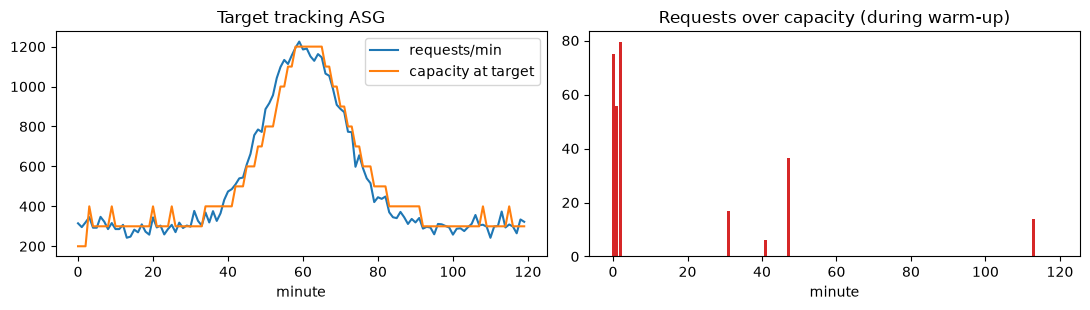

max instances: 12 | requests over capacity: 283


In [11]:
def simulate_asg(traffic, target_per_instance=100, min_n=2, max_n=20, warmup=3):
    """Target tracking: desired = ceil(load / target). New instances take `warmup` steps to be ready."""
    ready, pending, history = min_n, deque(), []
    for t, load in enumerate(traffic):
        while pending and pending[0] <= t:               # instances that finished warming up
            pending.popleft(); ready += 1
        desired = int(np.clip(math.ceil(load / target_per_instance), min_n, max_n))
        total = ready + len(pending)
        if desired > total:                              # scale out: launch now, ready later
            pending.extend([t + warmup] * (desired - total))
        elif desired < ready and not pending:            # scale in (gently: one at a time)
            ready -= 1
        served = min(load, ready * target_per_instance * 1.2)   # each instance can burst 20% above target
        history.append({"t": t, "load": load, "ready": ready, "pending": len(pending), "dropped": load - served})
    return pd.DataFrame(history)

minutes = np.arange(120)
traffic = 300 + 900 * np.exp(-((minutes - 60) / 15) ** 2) + np.random.normal(0, 30, 120)   # illustrative spike
sim = simulate_asg(np.maximum(traffic, 0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(sim.t, sim.load, label="requests/min"); ax[0].plot(sim.t, sim.ready * 100, label="capacity at target")
ax[0].set_title("Target tracking ASG"); ax[0].legend(); ax[0].set_xlabel("minute")
ax[1].bar(sim.t, sim.dropped, color="tab:red"); ax[1].set_title("Requests over capacity (during warm-up)"); ax[1].set_xlabel("minute")
plt.tight_layout(); plt.show()
print("max instances:", sim.ready.max(), "| requests over capacity:", int(sim.dropped.sum()))

The red bars are the cost of **warm-up time**. Fixes: a higher `min`, scheduled scaling before known peaks, warm pools, or a faster-booting image. For GPU model servers, model loading time is often the biggest part of warm-up.

### 5.3 Elastic Load Balancing: ALB vs NLB

| | **Application Load Balancer (ALB)** | **Network Load Balancer (NLB)** | Gateway LB |
|---|---|---|---|
| Layer | 7 (HTTP/HTTPS, gRPC, WebSocket) | 4 (TCP, UDP, TLS) | 3 (for firewalls/appliances) |
| Routing | by path, host, header, query string; weighted target groups | by port; very high throughput, static IPs | to inspection appliances |
| Good for | REST / streaming LLM APIs, canary releases, Cognito/OIDC login at the edge of the app | gRPC/TCP model servers needing static IPs, PrivateLink services, extreme connection counts | security appliances |
| Targets | instances, IPs, Lambda, ECS tasks | instances, IPs, ALB | appliances |

Both do **health checks** and spread traffic across AZs. For long LLM responses, raise the ALB **idle timeout** (default 60 s) or stream tokens so the connection is not idle.

### 5.4 AWS Lambda

**What it is.** Run a function without managing servers. Pay per request and per millisecond of compute. Triggered by API Gateway, function URLs, S3, SQS, EventBridge, DynamoDB Streams, and more. Covered for ML serving in [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb) (cold starts, container images).

Key facts (check current quotas): max **15 minutes** per invocation (standard Lambda), up to 10 GB memory (CPU scales with memory), container images up to 10 GB, `/tmp` up to 10 GB. Features: **layers**, **SnapStart** (snapshot an initialised function to cut cold starts), **provisioned concurrency** (pre-warmed), **reserved concurrency** (a cap), **response streaming** (good for LLM tokens).

**Newer options (re:Invent 2025):**
- **Lambda durable functions:** write a multi-step workflow as normal code. The function **checkpoints** progress, can **wait** for a timer, a callback or a human approval (for up to a year) without paying for compute while waiting, then resumes. Good for agent workflows with human-in-the-loop steps. Started with Python and Node.js.
- **Lambda Managed Instances:** run Lambda functions on **EC2 instance types you choose** (still managed by Lambda: patching, scaling, routing). Useful for steady high-volume traffic, special hardware, or when you want EC2 pricing models with the Lambda programming model. Longer timeouts are supported for some invocation types on Managed Instances.

**When to use Lambda.** Glue code, event processing, light CPU inference, calling Bedrock. **When not.** Large GPU models (no GPUs on Lambda), long steady heavy traffic where containers are cheaper.

### 5.5 Containers: ECR, ECS, Fargate, ECS Express Mode

- **Amazon ECR:** private container registry (image scanning, lifecycle rules, pull-through cache).
- **Amazon ECS:** AWS's own container orchestrator. You define a **task definition** (image, CPU/memory, env, **task role**, **execution role**) and a **service** (how many tasks, behind which load balancer).
- **Capacity:** **Fargate** (serverless, no instances to manage; no GPUs) or **EC2 launch type / capacity providers** (your instances, needed for GPUs), or **ECS Managed Instances**.
- **ECS Express Mode:** give it a container image, and it sets up a Fargate service with an ALB, HTTPS, autoscaling and logging for you. **AWS App Runner** is closed to new customers since 30 April 2026, and AWS points to ECS Express Mode as the replacement.

Two roles that people mix up: the **task execution role** lets ECS pull the image and write logs. The **task role** is what *your code* uses (for example to call Bedrock).

### 5.6 Amazon EKS

**What it is.** Managed **Kubernetes**: AWS runs the control plane, you run workloads (Kubernetes is covered in [17_Docker/kubernetes](../17_Docker/kubernetes) and [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb)).
- **Node options:** managed node groups, self-managed nodes, Fargate profiles, **Karpenter** (fast just-in-time node provisioning), and **EKS Auto Mode**, where AWS also manages nodes, scaling (Karpenter-based), load balancer controller, storage driver and core add-ons.
- **Pod permissions:** **EKS Pod Identity** (recommended for new work, agent preinstalled in Auto Mode: associate an IAM role with a Kubernetes service account through the EKS API) or **IRSA** (IAM Roles for Service Accounts: older, OIDC-federation based, still widely used).
- **GPUs:** GPU AMIs, NVIDIA device plugin or DRA, node pools for `p`/`g` instances, EFA for multi-node training.

### 5.7 AWS Batch

**What it is.** A managed **job queue** for batch work. You submit jobs (containers), Batch picks instances (EC2, Spot, Fargate, or EKS) and runs them. Supports array jobs, multi-node parallel jobs, priorities and fair-share scheduling. Good for offline embedding generation, nightly scoring, simulations.

### 5.8 Which compute should I pick?

In [12]:
def pick_compute(needs_gpu, steady_traffic, max_runtime_min, team_knows_k8s, want_minimal_ops, batch_jobs=False):
    """A rule-of-thumb chooser. Real decisions also weigh cost, latency and compliance."""
    if batch_jobs:
        return "AWS Batch (or SageMaker processing/batch transform for ML-specific jobs)"
    if needs_gpu:
        if team_knows_k8s: return "EKS (Auto Mode or Karpenter) with GPU node pools"
        return "ECS on EC2 GPU capacity, or a SageMaker AI endpoint"
    if max_runtime_min <= 15 and not steady_traffic:
        return "Lambda"
    if want_minimal_ops:
        return "ECS Express Mode / ECS on Fargate"
    if team_knows_k8s:
        return "EKS"
    return "ECS on Fargate (or Lambda Managed Instances if you like the Lambda model)"

cases = [
    dict(needs_gpu=False, steady_traffic=False, max_runtime_min=1,  team_knows_k8s=False, want_minimal_ops=True),
    dict(needs_gpu=False, steady_traffic=True,  max_runtime_min=60, team_knows_k8s=False, want_minimal_ops=True),
    dict(needs_gpu=True,  steady_traffic=True,  max_runtime_min=60, team_knows_k8s=True,  want_minimal_ops=False),
    dict(needs_gpu=True,  steady_traffic=False, max_runtime_min=60, team_knows_k8s=False, want_minimal_ops=True),
    dict(needs_gpu=False, steady_traffic=False, max_runtime_min=600, team_knows_k8s=False, want_minimal_ops=True, batch_jobs=True),
]
pd.DataFrame([{**{"batch_jobs": False}, **c, "pick": pick_compute(**c)} for c in cases])

,batch_jobs,needs_gpu,steady_traffic,max_runtime_min,team_knows_k8s,want_minimal_ops,pick
0,False,False,False,1,False,True,Lambda
1,False,False,True,60,False,True,ECS Express Mode / ECS on Fargate
2,False,True,True,60,True,False,EKS (Auto Mode or Karpenter) with GPU node pools
3,False,True,False,60,False,True,"ECS on EC2 GPU capacity, or a SageMaker AI endpoint"
4,True,False,False,600,False,True,AWS Batch (or SageMaker processing/batch transform for ML-specific jobs)


## 6. Storage and databases

### 6.1 Amazon S3

**What it is.** Object storage: put files (**objects**, up to 5 TB each) into **buckets**, addressed by a **key** like `datasets/v3/train.parquet`. 11 nines of designed durability. S3 is where training data, model artifacts, logs and batch-inference inputs usually live.

**Storage classes** (cheapest per GB at the bottom, but with retrieval fees or delays):

| Class | Use for |
|---|---|
| S3 Standard | hot data, frequently read |
| S3 Intelligent-Tiering | unknown or changing access patterns (moves objects between tiers automatically) |
| S3 Express One Zone | very low-latency, single-AZ, high request rates (for example training data loaders, checkpoints) |
| S3 Standard-IA / One Zone-IA | infrequently accessed, but needed fast when it is |
| S3 Glacier Instant Retrieval | archive with millisecond access |
| S3 Glacier Flexible Retrieval / Deep Archive | archive, minutes to hours to restore |

**Key features.** **Lifecycle rules** (move to cheaper classes after N days, expire old versions), **versioning** (keep every version; protects against overwrite/delete), **Object Lock** (write-once-read-many), **replication** (same/cross-Region), **presigned URLs** (time-limited links to upload/download one object), **bucket policies** + **Block Public Access** (keep it on), **encryption** (SSE-S3 default, SSE-KMS for key control), **S3 Event Notifications** (trigger Lambda/SQS/EventBridge on upload), **Mountpoint for S3** (mount a bucket as a file system for read-heavy training).

Below: a lifecycle simulation with **illustrative, made-up** relative prices (Standard = 1.00 unit per GB-month).

In [13]:
# ILLUSTRATIVE relative storage prices (not real AWS prices).
PRICE = {"STANDARD": 1.00, "STANDARD_IA": 0.55, "GLACIER_IR": 0.18, "DEEP_ARCHIVE": 0.04}
lifecycle = [(0, "STANDARD"), (30, "STANDARD_IA"), (90, "GLACIER_IR"), (365, "DEEP_ARCHIVE")]

def class_at(age_days):
    cls = lifecycle[0][1]
    for start, c in lifecycle:
        if age_days >= start: cls = c
    return cls

# Each month the team writes 2 TB of new logs/checkpoints. Compare 24 months with and without the rule.
months, new_tb = 24, 2.0
with_rule = without = 0.0
for m in range(months):
    for written in range(m + 1):                     # data written in month `written` is (m - written) months old
        age = (m - written) * 30
        with_rule += new_tb * 1024 * PRICE[class_at(age)]
        without   += new_tb * 1024 * PRICE["STANDARD"]
print(f"storage cost units over {months} months: no lifecycle={without:,.0f}  with lifecycle={with_rule:,.0f}  "
      f"saving={1 - with_rule / without:.0%} (illustrative)")

storage cost units over 24 months: no lifecycle=614,400  with lifecycle=166,072  saving=73% (illustrative)


### 6.2 Amazon S3 Vectors

**What it is.** A bucket type for **vector embeddings** (GA December 2025). You create a **vector bucket**, then **vector indexes** inside it (dimension and distance metric: cosine or Euclidean), then put vectors with metadata and query by similarity with metadata filters. AWS states up to 2 billion vectors per index and 10,000 indexes per vector bucket (check current limits).

**Analogy.** A huge, cheap filing cabinet for embeddings. Slower to search than a dedicated in-memory vector database, but you pay mainly for storage and queries, not for always-on servers.

**When to use.** Large RAG corpora that are queried at modest rates, as a **Bedrock Knowledge Bases** vector store, or as a cold tier behind OpenSearch. **When not.** Very high query rates with single-digit-millisecond latency, or hybrid keyword + vector search (use OpenSearch). Vector database theory is in [Vector databases](../22_ML_System_Design/05_vector_databases.ipynb).

```python
# Shown only (needs AWS credentials). boto3 client name: "s3vectors"
import boto3
s3v = boto3.client("s3vectors")
s3v.create_vector_bucket(vectorBucketName="kb-vectors")
s3v.create_index(vectorBucketName="kb-vectors", indexName="docs", dataType="float32",
                 dimension=1024, distanceMetric="cosine")
s3v.put_vectors(vectorBucketName="kb-vectors", indexName="docs",
                vectors=[{"key": "doc1#0", "data": {"float32": embedding}, "metadata": {"source": "hr.pdf"}}])
s3v.query_vectors(vectorBucketName="kb-vectors", indexName="docs", queryVector={"float32": q},
                  topK=5, filter={"source": "hr.pdf"}, returnMetadata=True)
```

### 6.3 Block and file storage: EBS, EFS, FSx for Lustre

| Service | Type | Attach to | AI use |
|---|---|---|---|
| **EBS** (gp3, io2) | block disk, one AZ | usually one EC2 instance | OS disk, local datasets, model weights for one server |
| **Instance store** | local NVMe, lost on stop | one instance | fast scratch space, caches |
| **EFS** | shared NFS file system, multi-AZ, elastic | many EC2 / ECS / Lambda / EKS | shared notebooks, small model files across containers |
| **FSx for Lustre** | high-performance parallel file system, can link to an S3 bucket | many instances (HPC/ML clusters) | feeding GPUs fast during distributed training, checkpoints |
| FSx for NetApp ONTAP / Windows / OpenZFS | managed enterprise file systems | many | lift-and-shift |

### 6.4 Relational: RDS and Aurora

- **Amazon RDS:** managed PostgreSQL, MySQL, MariaDB, SQL Server, Oracle, Db2. Automated backups, **Multi-AZ** standby for failover, **read replicas** for scale-out reads.
- **Amazon Aurora:** AWS's cloud-native MySQL/PostgreSQL-compatible engine. Storage is replicated 6 ways across 3 AZs. **Aurora Serverless v2** scales capacity in small steps (and can scale to zero in supported versions). **Global Database** for multi-Region. **Aurora DSQL** is a newer serverless distributed SQL option. Aurora PostgreSQL supports **pgvector**, so one database can hold both app data and embeddings.
- Background on SQL is in [13_Databases](../13_Databases) and [Relational DB design](../22_ML_System_Design/03_relational_db_design.ipynb).

### 6.5 DynamoDB design basics

**What it is.** A serverless key-value / document database with single-digit-millisecond reads at any scale. Every item has a **partition key** (PK) and optionally a **sort key** (SK). You can only query efficiently **by PK** (and a range of SK). Other access patterns need **global secondary indexes (GSIs)**. Capacity: **on-demand** or **provisioned** (with auto scaling). Extras: TTL (auto-delete old items), Streams (change feed), global tables (multi-Region), transactions.

**Analogy.** A giant wall of post-office boxes. The PK is the box number (it decides which shelf, or partition, the box sits on). The SK sorts the letters inside the box.

**Design rule.** Write down your **access patterns first**, then choose keys. Avoid **hot partitions** (one PK getting most of the traffic). Below: a single-table design for chat sessions of an AI assistant, plus a hot-partition check.

In [14]:
class TinyDynamo:
    """A dict-of-sorted-lists stand-in for one DynamoDB table (no real AWS)."""
    def __init__(self): self.parts = defaultdict(dict)
    def put(self, item): self.parts[item["PK"]][item["SK"]] = item
    def query(self, pk, sk_begins_with="", limit=None, newest_first=False):
        keys = sorted(k for k in self.parts[pk] if k.startswith(sk_begins_with))
        if newest_first: keys = keys[::-1]
        return [self.parts[pk][k] for k in keys[:limit]]

t = TinyDynamo()
t.put({"PK": "USER#ana", "SK": "PROFILE", "plan": "pro"})
for i, msg in enumerate(["hi", "summarise my PDF", "make it shorter"]):
    t.put({"PK": "USER#ana", "SK": f"SESSION#2026-11-13#MSG#{i:04d}", "text": msg})
t.put({"PK": "USER#ana", "SK": "SESSION#2026-11-12#MSG#0000", "text": "old chat"})

print("Access pattern 1: get profile ->", t.query("USER#ana", "PROFILE"))
print("Access pattern 2: last 2 messages of today's session ->",
      [m["text"] for m in t.query("USER#ana", "SESSION#2026-11-13", limit=2, newest_first=True)])

# Hot partition check: how evenly would requests spread over partitions?
def partition_load(keys, n_partitions=8):
    load = np.zeros(n_partitions)
    for k in keys: load[int(hashlib.md5(k.encode()).hexdigest(), 16) % n_partitions] += 1
    return load.max() / load.mean()
bad  = ["MODEL#prod"] * 900 + [f"MODEL#exp{i}" for i in range(100)]   # everyone writes the same PK
good = [f"MODEL#prod#{random.randint(0, 31)}" for _ in range(900)] + [f"MODEL#exp{i}" for i in range(100)]  # write sharding
print(f"\nhottest partition vs average: bad key={partition_load(bad):.1f}x, sharded key={partition_load(good):.1f}x")

Access pattern 1: get profile -> [{'PK': 'USER#ana', 'SK': 'PROFILE', 'plan': 'pro'}]
Access pattern 2: last 2 messages of today's session -> ['make it shorter', 'summarise my PDF']

hottest partition vs average: bad key=7.4x, sharded key=1.6x


### 6.6 In-memory: ElastiCache, MemoryDB, Valkey

- **Amazon ElastiCache:** managed in-memory cache, engines **Valkey** (the open-source, Linux Foundation fork of Redis, now AWS's recommended engine), Redis OSS and Memcached. Serverless or node-based. Recent Valkey versions add vector search and full-text search features.
- **Amazon MemoryDB:** a **durable** Redis/Valkey-compatible database (multi-AZ transaction log), so you can use it as a primary database, with vector search.
- **AI uses:** response cache and **semantic cache** for LLM calls, rate limiting, session state, feature serving, leaderboards.

Other databases you will meet: **OpenSearch Service** (search + vector engine; Serverless option), **DocumentDB** (MongoDB-compatible), **Neptune** (graphs, GraphRAG), **Redshift** (data warehouse), **Timestream** (time series), **Keyspaces** (Cassandra). Analytics services (Glue, Athena, EMR, Lake Formation, Kinesis) are summarised in [AWS for AI/ML](01_aws_for_ai.ipynb).

| Need | Pick |
|---|---|
| Relational app data, joins, transactions | Aurora / RDS PostgreSQL |
| Key-value at huge scale, predictable access patterns | DynamoDB |
| Sub-millisecond cache, semantic cache | ElastiCache (Valkey) |
| Durable in-memory database | MemoryDB |
| Full-text + vector + hybrid search | OpenSearch Service |
| Cheap, large-scale vector storage | S3 Vectors |
| Vectors next to relational data | Aurora PostgreSQL + pgvector |

## 7. Integration: queues, events, workflows

| Service | Pattern | Analogy | AI use |
|---|---|---|---|
| **SQS** | **queue**: one message is processed by one consumer. Standard (at-least-once, best-effort order) or FIFO (ordered, exactly-once processing within limits). **Visibility timeout**, **dead-letter queue (DLQ)**. | A ticket machine at a bakery: each ticket is served once. | Buffer GPU inference jobs, absorb traffic spikes, retry failed jobs. |
| **SNS** | **pub/sub fan-out**: one message to many subscribers (SQS, Lambda, HTTP, email, SMS). | A loudspeaker announcement. | "New model approved" to several systems. |
| **EventBridge (event bus + rules)** | route **events** by content to targets. Gets events from AWS services, SaaS partners, your apps. | A post room that reads each envelope and sends it to the right desk. | "SageMaker model package approved" triggers a deploy pipeline. |
| **EventBridge Scheduler** | cron / one-time schedules that call 200+ AWS APIs, with retries and time zones. | An alarm clock that can press buttons. | Nightly batch inference, re-index the knowledge base. |
| **EventBridge Pipes** | point-to-point: **source -> filter -> enrich -> target** without glue code. | A conveyor belt with a sorting gate. | DynamoDB stream -> filter -> Lambda enrich -> Step Functions. |
| **Step Functions** | **workflow** as a state machine (JSON "Amazon States Language"): tasks, choices, parallel, map, retries, catch, wait, human approval with task tokens. Standard (long, exactly-once) vs Express (high volume, short). | A recipe card with checkboxes. | Document pipeline: Textract -> chunk -> embed -> index, with retries. |
| **MWAA** (Amazon Managed Workflows for Apache Airflow) | managed Airflow (DAGs in Python); provisioned environments and a newer **MWAA Serverless** option. | A factory schedule board. | Data and training pipelines, when the team already uses Airflow. See [Pipeline orchestration](../15_MLOps/03_pipeline_orchestration). |

### 7.1 Runnable: SQS visibility timeout, retries and a DLQ

In [15]:
class ToySQS:
    """A queue with visibility timeout and a dead-letter queue (maxReceiveCount)."""
    def __init__(self, visibility=3, max_receive=3):
        self.msgs, self.dlq, self.vis, self.max_rx, self.clock = [], [], visibility, max_receive, 0
    def send(self, body): self.msgs.append({"id": len(self.msgs), "body": body, "visible_at": 0, "rx": 0})
    def receive(self):
        for m in self.msgs:
            if m["visible_at"] <= self.clock:
                m["rx"] += 1
                if m["rx"] > self.max_rx:                  # received too many times -> DLQ
                    self.msgs.remove(m); self.dlq.append(m); return self.receive()
                m["visible_at"] = self.clock + self.vis    # hidden while a worker processes it
                return m
        return None
    def delete(self, m): self.msgs.remove(m)               # the worker must delete on success

def worker(msg):
    if "corrupt" in msg["body"]: raise ValueError("cannot parse")   # a poison message
    return f"embedded {msg['body']}"

q = ToySQS()
for b in ["doc-1.pdf", "doc-2.pdf", "corrupt.pdf", "doc-3.pdf"]: q.send(b)
log = []
for tick in range(15):
    q.clock = tick
    m = q.receive()
    if m is None: continue
    try:
        log.append(f"t={tick:2d} {worker(m)}"); q.delete(m)
    except ValueError as e:
        log.append(f"t={tick:2d} FAILED {m['body']} (receive #{m['rx']}): {e}")
print("\n".join(log))
print("dead-letter queue:", [m["body"] for m in q.dlq])

t= 0 embedded doc-1.pdf
t= 1 embedded doc-2.pdf
t= 2 FAILED corrupt.pdf (receive #1): cannot parse
t= 3 embedded doc-3.pdf
t= 5 FAILED corrupt.pdf (receive #2): cannot parse
t= 8 FAILED corrupt.pdf (receive #3): cannot parse
dead-letter queue: ['corrupt.pdf']


**Rule.** Set the visibility timeout **longer** than your worst-case processing time (for example 6x the average), or the same message will be processed twice. Make handlers **idempotent** (safe to run twice), because standard queues are at-least-once.

### 7.2 Runnable: EventBridge rule matching

EventBridge rules use **event patterns**: JSON that the event must match. Lists mean "any of these values". Prefix and numeric matching exist too.

In [16]:
def matches(pattern, event):
    """Subset of EventBridge pattern rules: exact values in lists, {"prefix": ...}, {"numeric": [">", x]}, nesting."""
    for key, want in pattern.items():
        if key not in event: return False
        got = event[key]
        if isinstance(want, dict):
            if not isinstance(got, dict) or not matches(want, got): return False
        else:
            ok = False
            for w in want:
                if isinstance(w, dict) and "prefix" in w: ok |= isinstance(got, str) and got.startswith(w["prefix"])
                elif isinstance(w, dict) and "numeric" in w:
                    op, val = w["numeric"]; ok |= {">": got > val, ">=": got >= val, "<": got < val}[op]
                else: ok |= got == w
            if not ok: return False
    return True

rule_deploy = {"source": ["aws.sagemaker"], "detail-type": ["SageMaker Model Package State Change"],
               "detail": {"ModelApprovalStatus": ["Approved"], "ModelPackageGroupName": [{"prefix": "fraud-"}]}}
rule_cost   = {"source": ["my.ai-api"], "detail": {"tokens": [{"numeric": [">", 100000]}]}}
events = [
    {"source": "aws.sagemaker", "detail-type": "SageMaker Model Package State Change",
     "detail": {"ModelApprovalStatus": "Approved", "ModelPackageGroupName": "fraud-xgb"}},
    {"source": "aws.sagemaker", "detail-type": "SageMaker Model Package State Change",
     "detail": {"ModelApprovalStatus": "Rejected", "ModelPackageGroupName": "fraud-xgb"}},
    {"source": "my.ai-api", "detail": {"tokens": 250000, "tenant": "acme"}},
]
for e in events:
    print(f"{e['source']:14s} {str(e['detail'])[:60]:62s} deploy-rule={matches(rule_deploy, e)} cost-alert={matches(rule_cost, e)}")

aws.sagemaker  {'ModelApprovalStatus': 'Approved', 'ModelPackageGroupName':   deploy-rule=True cost-alert=False
aws.sagemaker  {'ModelApprovalStatus': 'Rejected', 'ModelPackageGroupName':   deploy-rule=False cost-alert=False
my.ai-api      {'tokens': 250000, 'tenant': 'acme'}                           deploy-rule=False cost-alert=True


### 7.3 Runnable: a tiny Step Functions interpreter

A mini interpreter for a subset of the Amazon States Language: `Task` (with `Retry` and `Catch`), `Choice`, `Succeed`, `Fail`. It runs a document-ingestion workflow with a flaky OCR step.

In [17]:
attempts = defaultdict(int)
def ocr(x):
    attempts["ocr"] += 1
    if attempts["ocr"] < 3: raise TimeoutError("OCR service busy")   # fails twice, then works
    return {**x, "text": "Invoice total: 420 EUR", "pages": 2}
def classify(x): return {**x, "doc_type": "invoice" if "Invoice" in x["text"] else "other"}
def index(x):    return {**x, "indexed": True}
TASKS = {"ocr": ocr, "classify": classify, "index": index}

machine = {"StartAt": "OCR", "States": {
    "OCR":      {"Type": "Task", "Resource": "ocr", "Next": "Classify",
                 "Retry": [{"ErrorEquals": ["TimeoutError"], "MaxAttempts": 3, "IntervalSeconds": 1, "BackoffRate": 2.0}],
                 "Catch": [{"ErrorEquals": ["States.ALL"], "Next": "Failed"}]},
    "Classify": {"Type": "Task", "Resource": "classify", "Next": "IsInvoice"},
    "IsInvoice":{"Type": "Choice", "Choices": [{"Variable": "$.doc_type", "StringEquals": "invoice", "Next": "Index"}],
                 "Default": "Done"},
    "Index":    {"Type": "Task", "Resource": "index", "Next": "Done"},
    "Done":     {"Type": "Succeed"},
    "Failed":   {"Type": "Fail", "Error": "IngestFailed"}}}

def run(machine, data):
    state, trace, waited = machine["StartAt"], [], 0.0
    while True:
        s = machine["States"][state]; trace.append(state)
        if s["Type"] == "Succeed": return data, trace, waited
        if s["Type"] == "Fail": return {"error": s["Error"]}, trace, waited
        if s["Type"] == "Choice":
            nxt = s["Default"]
            for c in s["Choices"]:
                if data.get(c["Variable"][2:]) == c["StringEquals"]: nxt = c["Next"]; break
            state = nxt; continue
        retry = (s.get("Retry") or [{"ErrorEquals": [], "MaxAttempts": 0}])[0]
        for attempt in range(retry["MaxAttempts"] + 1):
            try:
                data = TASKS[s["Resource"]](data); state = s["Next"]; break
            except Exception as e:
                if type(e).__name__ in retry["ErrorEquals"] and attempt < retry["MaxAttempts"]:
                    wait = retry["IntervalSeconds"] * retry["BackoffRate"] ** attempt
                    waited += wait; trace.append(f"  retry after {wait:.0f}s ({e})"); continue
                handler = next((c for c in s.get("Catch", []) if "States.ALL" in c["ErrorEquals"]), None)
                if handler: state = handler["Next"]; break
                raise

out, trace, waited = run(machine, {"s3_key": "inbox/inv-77.pdf"})
print("path:", " -> ".join(t for t in trace if not t.startswith("  ")))
print("\n".join(t for t in trace if t.startswith("  ")))
print("output:", out, f"| total back-off waited: {waited:.0f}s (simulated)")

path: OCR -> Classify -> IsInvoice -> Index -> Done
  retry after 1s (OCR service busy)
  retry after 2s (OCR service busy)
output: {'s3_key': 'inbox/inv-77.pdf', 'text': 'Invoice total: 420 EUR', 'pages': 2, 'doc_type': 'invoice', 'indexed': True} | total back-off waited: 3s (simulated)


## 8. Observability and governance: CloudWatch, CloudTrail, Config

| Service | Answers the question | Key parts |
|---|---|---|
| **CloudWatch Metrics** | "How is it behaving right now?" | namespaces (`AWS/Lambda`, `AWS/Bedrock`, custom), dimensions, statistics (p50/p99), **alarms**, **dashboards**, anomaly detection, Embedded Metric Format (metrics from JSON logs) |
| **CloudWatch Logs** | "What exactly happened?" | log groups, streams, retention, metric filters, subscription filters, **Logs Insights** (query language), Live Tail |
| **Container Insights** | "How are my ECS/EKS containers doing?" | CPU/memory/GPU per task/pod/node, enhanced observability for EKS |
| **Application Signals / X-Ray** | "Where is the latency?" | traces and service maps, SLOs, OpenTelemetry-based (agent tracing is in [Agent observability](../10_Agents/06_agent_observability.ipynb)) |
| **CloudWatch generative AI observability** | "How are my model calls and agents doing?" | model invocation dashboards (needs Bedrock **model invocation logging**), AgentCore agent views |
| **CloudTrail** | "**Who** did **what**, **when**, from **where**?" | management events (API calls like `CreateBucket`, `PutRolePolicy`), data events (S3 object reads, Lambda invokes; extra cost), organisation trails, CloudTrail Lake (SQL over events) |
| **AWS Config** | "Is my setup **compliant**, and how did it change?" | configuration history of resources, **Config rules** (managed and custom), conformance packs, auto-remediation |

**Analogy.** CloudWatch is the car dashboard and the black-box recorder of the engine. CloudTrail is the security-camera log of who opened which door. Config is the inspector with a checklist who also keeps photos of how the building looked every day.

### 8.1 Runnable: a "Logs Insights" style query with pandas

A CloudWatch Logs Insights query for an LLM API might look like:

```
fields @timestamp, route, latency_ms, status, output_tokens
| filter route = "/chat"
| stats count(*) as requests, avg(latency_ms) as avg_ms, pct(latency_ms, 95) as p95_ms,
        sum(status >= 500) as errors by bin(5m)
```

The same thing on fake JSON logs with pandas:

In [18]:
n = 600
start = datetime(2026, 11, 13, 12, 0)
logs = pd.DataFrame({
    "@timestamp": [start + timedelta(seconds=int(s)) for s in np.sort(np.random.randint(0, 1800, n))],
    "route": np.random.choice(["/chat", "/embed"], n, p=[0.7, 0.3]),
    "latency_ms": np.random.lognormal(6.3, 0.5, n).round(),
    "status": np.random.choice([200, 429, 500], n, p=[0.95, 0.03, 0.02]),
    "output_tokens": np.random.randint(20, 800, n),
})
logs.loc[logs["@timestamp"] > start + timedelta(minutes=20), "latency_ms"] *= 1.8   # a slowdown starts at 12:20

chat = logs[logs.route == "/chat"].set_index("@timestamp")
report = chat.resample("5min").agg(requests=("route", "size"), avg_ms=("latency_ms", "mean"),
                                   p95_ms=("latency_ms", lambda s: np.percentile(s, 95)),
                                   errors=("status", lambda s: int((s >= 500).sum())))
print(report.round(0))
# A CloudWatch alarm would be: p95_ms > 1500 for 2 consecutive periods.
alarm = (report.p95_ms > 1500).rolling(2).sum() == 2
print("\nALARM periods:", list(report.index[alarm].strftime("%H:%M")))

                     requests  avg_ms  p95_ms  errors
@timestamp                                           
2026-11-13 12:00:00        53   669.0  1397.0       2
2026-11-13 12:05:00        72   638.0  1315.0       1
2026-11-13 12:10:00        78   680.0  1268.0       2
2026-11-13 12:15:00        86   619.0  1294.0       1
2026-11-13 12:20:00        79  1046.0  1833.0       1
2026-11-13 12:25:00        61  1262.0  2682.0       2

ALARM periods: ['12:25']


### 8.2 Runnable: a mini "Config rule" check

In [19]:
# Pretend inventory of resources, like AWS Config would record.
inventory = [
    {"type": "AWS::S3::Bucket", "id": "ml-data",       "public": False, "encrypted": True,  "versioning": True},
    {"type": "AWS::S3::Bucket", "id": "tmp-exports",   "public": True,  "encrypted": True,  "versioning": False},
    {"type": "AWS::EC2::Instance", "id": "i-gpu-01",   "imdsv2": False, "tags": {"team": "ml"}},
    {"type": "AWS::EC2::Instance", "id": "i-api-02",   "imdsv2": True,  "tags": {}},
    {"type": "AWS::CloudTrail::Trail", "id": "org-trail", "multi_region": True, "log_validation": True},
]
RULES = {  # rule name -> (resource type, check)
    "s3-bucket-public-read-prohibited": ("AWS::S3::Bucket", lambda r: not r["public"]),
    "s3-bucket-versioning-enabled":     ("AWS::S3::Bucket", lambda r: r["versioning"]),
    "ec2-imdsv2-check":                 ("AWS::EC2::Instance", lambda r: r["imdsv2"]),
    "required-tags (team)":             ("AWS::EC2::Instance", lambda r: "team" in r["tags"]),
    "cloudtrail-multi-region":          ("AWS::CloudTrail::Trail", lambda r: r["multi_region"]),
}
rows = [{"rule": name, "resource": r["id"], "result": "COMPLIANT" if check(r) else "NON_COMPLIANT"}
        for name, (rtype, check) in RULES.items() for r in inventory if r["type"] == rtype]
res = pd.DataFrame(rows)
print(res[res.result == "NON_COMPLIANT"].to_string(index=False))

                            rule    resource        result
s3-bucket-public-read-prohibited tmp-exports NON_COMPLIANT
    s3-bucket-versioning-enabled tmp-exports NON_COMPLIANT
                ec2-imdsv2-check    i-gpu-01 NON_COMPLIANT
            required-tags (team)    i-api-02 NON_COMPLIANT


## 9. Infrastructure as code: CloudFormation, CDK, SAM

**What it is.** Describe infrastructure in files, keep them in Git, and let a tool create, update and delete resources to match. (General IaC and Terraform are covered in the DevOps material; here we focus on AWS-native tools.)

| Tool | You write | It produces | Best for |
|---|---|---|---|
| **CloudFormation** | YAML/JSON **templates** | **stacks** (a group of resources). **Change sets** preview changes. **StackSets** deploy to many accounts/Regions. Drift detection. | The base layer everything else compiles to. |
| **AWS CDK** | TypeScript, Python, Java, Go, C# code using **constructs** (L1 = raw, L2 = sensible defaults, L3 = patterns) | CloudFormation templates (`cdk synth`) | Teams that prefer real code, loops, tests. |
| **AWS SAM** | CloudFormation + a short **serverless** syntax (`AWS::Serverless::Function`, `Api`) | CloudFormation; `sam local invoke` runs Lambda in Docker locally | Lambda + API Gateway apps. |
| Terraform / OpenTofu | HCL | provider API calls, state file | Multi-cloud teams. |

**SAM template for a small Bedrock-backed function** (shown, not deployed):

```yaml
AWSTemplateFormatVersion: "2010-09-09"
Transform: AWS::Serverless-2016-10-31
Resources:
  ChatFunction:
    Type: AWS::Serverless::Function
    Properties:
      Runtime: python3.13
      Handler: app.handler
      MemorySize: 1024
      Timeout: 60
      Policies:
        - Statement:
            - Effect: Allow
              Action: bedrock:InvokeModel
              Resource: "*"          # tighten to specific model / inference-profile ARNs
      Events:
        Chat:
          Type: HttpApi
          Properties: {Path: /chat, Method: post}
```

**CDK in Python** (shown, needs `aws-cdk-lib` and an AWS account):

```python
from aws_cdk import Stack, aws_ec2 as ec2, aws_ecs as ecs, aws_ecs_patterns as patterns
from constructs import Construct

class AiApiStack(Stack):
    def __init__(self, scope: Construct, id: str, **kw):
        super().__init__(scope, id, **kw)
        vpc = ec2.Vpc(self, "Vpc", max_azs=2, nat_gateways=1)            # public + private subnets for you
        cluster = ecs.Cluster(self, "Cluster", vpc=vpc, container_insights=True)
        patterns.ApplicationLoadBalancedFargateService(                  # an L3 construct: ALB + Fargate service
            self, "Api", cluster=cluster, cpu=1024, memory_limit_mib=2048, desired_count=2,
            task_image_options=patterns.ApplicationLoadBalancedTaskImageOptions(
                image=ecs.ContainerImage.from_asset("./service"), container_port=8080))
```

Commands: `cdk bootstrap` (once per account/Region), `cdk synth`, `cdk diff`, `cdk deploy`. For SAM: `sam build`, `sam local invoke`, `sam deploy --guided`.

In [20]:
# Runnable: generate a CloudFormation template from Python data (what CDK does, in miniature),
# and do a "change set" style diff between two versions.
def template(memory, with_alarm):
    res = {"ChatFn": {"Type": "AWS::Lambda::Function", "Properties": {"MemorySize": memory, "Timeout": 60, "Runtime": "python3.13"}}}
    if with_alarm:
        res["ErrorAlarm"] = {"Type": "AWS::CloudWatch::Alarm", "Properties": {"MetricName": "Errors", "Threshold": 5}}
    return {"AWSTemplateFormatVersion": "2010-09-09", "Resources": res}

def change_set(old, new):
    o, n = old["Resources"], new["Resources"]
    out = [("Add", k, n[k]["Type"]) for k in n if k not in o]
    out += [("Remove", k, o[k]["Type"]) for k in o if k not in n]
    out += [("Modify", k, f"{p}: {o[k]['Properties'].get(p)} -> {n[k]['Properties'].get(p)}")
            for k in n if k in o for p in n[k]["Properties"] if o[k]["Properties"].get(p) != n[k]["Properties"].get(p)]
    return out

v1, v2 = template(512, False), template(1024, True)
print(json.dumps(v2, indent=1)[:300], "...\n")
for action, logical_id, detail in change_set(v1, v2): print(f"{action:7s} {logical_id:11s} {detail}")

{
 "AWSTemplateFormatVersion": "2010-09-09",
 "Resources": {
  "ChatFn": {
   "Type": "AWS::Lambda::Function",
   "Properties": {
    "MemorySize": 1024,
    "Timeout": 60,
    "Runtime": "python3.13"
   }
  },
  "ErrorAlarm": {
   "Type": "AWS::CloudWatch::Alarm",
   "Properties": {
    "MetricName ...

Add     ErrorAlarm  AWS::CloudWatch::Alarm
Modify  ChatFn      MemorySize: 512 -> 1024


## 10. Edge and DNS: Route 53, CloudFront, Lambda@Edge

**Amazon Route 53** is AWS's DNS service and domain registrar. **Hosted zones** hold records (A, AAAA, CNAME, and **alias** records that point to AWS resources like an ALB or CloudFront). **Routing policies:** simple, weighted (canary 90/10), latency-based (nearest Region), failover (with **health checks**), geolocation, geoproximity, multivalue. **Route 53 Resolver** handles DNS inside VPCs and hybrid DNS.

**Amazon CloudFront** is the CDN (content delivery network): it caches content at edge locations close to users, terminates TLS, and protects origins (S3 via Origin Access Control, ALBs, API Gateway). It can also stream dynamic responses.

**Edge compute:**
| | CloudFront Functions | Lambda@Edge |
|---|---|---|
| Runtime | lightweight JavaScript | Node.js / Python |
| Runs at | edge locations (very many) | Regional edge caches |
| Limits | sub-millisecond, tiny | seconds, network access allowed |
| Use for | header rewrites, redirects, simple auth token checks, A/B cookie | auth with external calls, image resizing, origin selection |

**Analogy.** Route 53 is the phone book that can send you to the nearest open shop. CloudFront is a chain of local corner shops that keep popular items in stock, so you do not travel to the central warehouse.

In [21]:
# Runnable: Route 53 style weighted and failover routing.
endpoints = {"us-east-1": {"weight": 90, "healthy": True}, "eu-west-1": {"weight": 10, "healthy": True}}
def weighted_pick(eps, rng):
    alive = {k: v for k, v in eps.items() if v["healthy"]}           # health checks remove dead endpoints
    names, w = list(alive), np.array([alive[k]["weight"] for k in alive], float)
    return rng.choice(names, p=w / w.sum())
rng = np.random.default_rng(0)
print("normal :", pd.Series([weighted_pick(endpoints, rng) for _ in range(1000)]).value_counts().to_dict())
endpoints["us-east-1"]["healthy"] = False
print("us-east-1 health check failing:", pd.Series([weighted_pick(endpoints, rng) for _ in range(1000)]).value_counts().to_dict())

normal : {'us-east-1': 904, 'eu-west-1': 96}


us-east-1 health check failing: {'eu-west-1': 1000}


## 11. Security services

| Service | What it does (simple) | AI example |
|---|---|---|
| **Amazon Cognito** | Sign-up / sign-in for **your app's users** (user pools: OAuth2/OIDC tokens, social and SAML login) and temporary AWS credentials for them (identity pools). | Log users into your chat app; pass the JWT to API Gateway or an ALB; AgentCore Identity can use it too. |
| **AWS KMS** | Create and control **encryption keys**; keys never leave KMS unencrypted. Key policies + IAM decide who can use them. Automatic rotation. | Encrypt S3 training data, EBS volumes, SageMaker endpoints, Bedrock custom models with your own key (customer managed key, CMK). |
| **Secrets Manager** | Store secrets (DB passwords, third-party API keys) with **automatic rotation** and audit. (SSM **Parameter Store** is the simpler, cheaper option for config and non-rotating secrets.) | Store an external LLM provider key for a fallback path. |
| **GuardDuty** | Threat detection from CloudTrail, VPC flow logs, DNS logs, EKS/runtime and S3 data events, using ML and threat intel. | Alerts on stolen credentials calling Bedrock from an odd country, crypto-mining on GPU instances. |
| **Security Hub** | One place for security findings from GuardDuty, Inspector, Macie, Config and partners, with security standards checks (for example AWS Foundational Security Best Practices, CIS). | One dashboard for the whole org. |
| **Amazon Inspector** | Scans EC2, ECR container images and Lambda for software vulnerabilities (CVEs) and network exposure. | Scan your model-serving image on every push. |
| **Amazon Macie** | Finds sensitive data (PII) in S3 with ML. | Check a training-data bucket before fine-tuning. |
| **AWS WAF** | Web application firewall on CloudFront, ALB, API Gateway, AppSync, Cognito: managed rule groups (SQLi, bad bots), **rate-based rules**, geo blocks. | Rate-limit `/chat` per IP to stop cost-draining abuse. |
| **AWS Shield** | DDoS protection. **Standard** is automatic and free; **Advanced** adds response team, cost protection, more coverage. | Protect a public AI API. |
| **AWS Certificate Manager (ACM)** | Free public TLS certificates for ALB/CloudFront, auto-renewed. | HTTPS for the API. |

### 11.1 Runnable: envelope encryption (the KMS idea)

KMS uses **envelope encryption**: KMS gives you a fresh **data key** in two forms, plain and encrypted under a KMS key. You encrypt your big file locally with the plain data key, throw the plain key away, and store the **encrypted data key next to the file**. To read it, you ask KMS to decrypt the small data key. The big file never goes to KMS.

The toy below uses a SHA-256 based keystream, which is **not secure**. It only shows the flow. Real code uses KMS `GenerateDataKey` and an AES-GCM library (or the AWS Encryption SDK).

In [22]:
def toy_cipher(key: bytes, data: bytes) -> bytes:
    """XOR with a SHA-256 keystream. TEACHING ONLY - never use this for real data."""
    stream, counter = b"", 0
    while len(stream) < len(data):
        stream += hashlib.sha256(key + counter.to_bytes(8, "big")).digest(); counter += 1
    return bytes(a ^ b for a, b in zip(data, stream))

class ToyKMS:
    """Holds master keys that never leave 'KMS'. Every use is logged (like CloudTrail)."""
    def __init__(self): self._keys, self.audit = {"alias/ml-data": os.urandom(32)}, []
    def generate_data_key(self, key_id, caller):
        self.audit.append((caller, "GenerateDataKey", key_id))
        plain = os.urandom(32)
        return plain, toy_cipher(self._keys[key_id], plain)            # (plaintext key, encrypted key)
    def decrypt(self, key_id, encrypted_key, caller, allowed=("training-role",)):
        self.audit.append((caller, "Decrypt", key_id))
        if caller not in allowed: raise PermissionError(f"AccessDenied: {caller} cannot use {key_id}")
        return toy_cipher(self._keys[key_id], encrypted_key)

kms = ToyKMS()
plain_key, enc_key = kms.generate_data_key("alias/ml-data", "ingest-role")
blob = toy_cipher(plain_key, b"patient_id,label\n123,1\n456,0\n"); del plain_key   # encrypt locally, drop the key
stored = {"ciphertext": blob, "encrypted_data_key": enc_key}                        # what lands in S3

print("stored bytes look random:", stored["ciphertext"][:16].hex())
print("training-role reads:", toy_cipher(kms.decrypt("alias/ml-data", stored["encrypted_data_key"], "training-role"), stored["ciphertext"]))
try:
    kms.decrypt("alias/ml-data", stored["encrypted_data_key"], "intern-role")
except PermissionError as e:
    print(e)
print("audit log:", kms.audit)

stored bytes look random: c6d1ad153678589596fe79d5ed940f97
training-role reads: b'patient_id,label\n123,1\n456,0\n'
AccessDenied: intern-role cannot use alias/ml-data
audit log: [('ingest-role', 'GenerateDataKey', 'alias/ml-data'), ('training-role', 'Decrypt', 'alias/ml-data'), ('intern-role', 'Decrypt', 'alias/ml-data')]


### 11.2 Runnable: a WAF rate-based rule

In [23]:
def waf_rate_limit(requests, limit=100, window_s=300):
    """Block an IP once it sends more than `limit` requests in a sliding window (like a WAF rate-based rule)."""
    seen, blocked, decisions = defaultdict(deque), set(), []
    for ts, ip in requests:
        q = seen[ip]; q.append(ts)
        while q and q[0] <= ts - window_s: q.popleft()
        if len(q) > limit: blocked.add(ip)
        decisions.append("BLOCK" if ip in blocked else "ALLOW")
    return decisions, blocked

reqs = [(t, "198.51.100.7") for t in np.random.uniform(0, 300, 60)] + \
       [(t, "203.0.113.66") for t in np.random.uniform(0, 300, 400)]           # a scraper hammering /chat
reqs.sort()
dec, blocked = waf_rate_limit(reqs)
print("blocked IPs:", blocked, "| blocked requests:", dec.count("BLOCK"), "of", len(dec))

blocked IPs: {'203.0.113.66'} | blocked requests: 300 of 460


## 12. CI/CD on AWS: CodePipeline, CodeBuild, CodeDeploy, CodeArtifact

| Service | Role | Notes |
|---|---|---|
| **CodePipeline** | Orchestrates stages: source -> build -> test -> approve -> deploy. | Sources: GitHub/GitLab/Bitbucket (via CodeConnections), S3, ECR. V2 pipelines support triggers and variables. |
| **CodeBuild** | Runs build/test commands in managed containers (`buildspec.yml`). | Can also act as a managed runner for GitHub Actions jobs; GPU build images exist for some workloads. |
| **CodeDeploy** | Deploys to EC2/on-prem, Lambda and ECS with **blue/green** and **canary / linear** traffic shifting, automatic rollback on CloudWatch alarms. | Pairs with the strategies in [Safe model rollout](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb). |
| **CodeArtifact** | Private package repository for pip, npm, Maven, NuGet; can proxy PyPI. | Pin and approve ML libraries. |
| CodeCommit | Managed Git. | Closed to new customers in 2024, then AWS said it would keep it available again; most teams use GitHub/GitLab. Check current status. |

Many teams use **GitHub Actions** with **OIDC federation** to assume an AWS role (no stored keys) and then call CDK/SAM/Terraform. ML-specific CI/CD is in [CI/CD for ML](../15_MLOps/04_ci_cd_for_ml).

```yaml
# buildspec.yml for a model-serving image (shown only)
version: 0.2
phases:
  pre_build:
    commands:
      - aws ecr get-login-password | docker login --username AWS --password-stdin $ECR_URI
      - pip install -r requirements.txt && pytest -q tests/
  build:
    commands:
      - docker build -t $ECR_URI:$CODEBUILD_RESOLVED_SOURCE_VERSION .
      - docker push $ECR_URI:$CODEBUILD_RESOLVED_SOURCE_VERSION
artifacts:
  files: [imagedefinitions.json]
```

In [24]:
# Runnable: CodeDeploy-style canary with automatic rollback on an alarm.
def canary_deploy(new_error_rate, steps=(10, 50, 100), alarm_threshold=0.02, seed=1):
    rng = np.random.default_rng(seed)
    for pct in steps:
        reqs = 2000 * pct // 100
        errors = rng.binomial(reqs, new_error_rate)
        rate = errors / max(reqs, 1)
        print(f"  shift {pct:3d}% to new version: {errors} errors / {reqs} req = {rate:.1%}")
        if rate > alarm_threshold:
            return "ROLLED BACK (alarm fired)"
    return "DEPLOYED"
print("good release:", canary_deploy(0.005)); print("bad release :", canary_deploy(0.06))

  shift  10% to new version: 1 errors / 200 req = 0.5%
  shift  50% to new version: 9 errors / 1000 req = 0.9%
  shift 100% to new version: 7 errors / 2000 req = 0.4%
good release: DEPLOYED
  shift  10% to new version: 12 errors / 200 req = 6.0%
bad release : ROLLED BACK (alarm fired)


## 13. Reference architecture: an AI API on AWS

A typical production shape for a chat / RAG API that calls Bedrock (or a self-hosted model), as of late 2026. Every box is a choice; simpler variants are listed after the diagram.

```mermaid
flowchart LR
    U[Users / apps] --> R53[Route 53]
    R53 --> CF[CloudFront + WAF + Shield]
    CF --> ALB[ALB in public subnets<br/>TLS from ACM, Cognito/OIDC auth]
    subgraph VPC[VPC across 2-3 AZs]
      ALB --> SVC[ECS Fargate service / EKS<br/>FastAPI app, task role]
      SVC --> CACHE[(ElastiCache Valkey<br/>semantic cache, rate limits)]
      SVC --> DDB[(DynamoDB<br/>sessions, usage)]
      SVC --> VEC[(Vector store:<br/>OpenSearch / Aurora pgvector / S3 Vectors)]
      SVC --> VPCE[Interface endpoints:<br/>bedrock-runtime, secretsmanager, logs]
      SVC --> Q[SQS: long jobs]
      Q --> WRK[Workers: Lambda / ECS / Batch]
    end
    VPCE --> BR[Amazon Bedrock<br/>models, Guardrails, KB]
    VPCE --> SM[Secrets Manager / KMS]
    S3[(S3: documents, artifacts<br/>lifecycle + KMS)] --> ING[EventBridge -> Step Functions<br/>ingest: parse, chunk, embed]
    ING --> VEC
    SVC -.metrics, logs, traces.-> CW[CloudWatch + X-Ray / OTel]
    ALL[All accounts] -.-> CT[CloudTrail, Config, GuardDuty, Security Hub]
```

**Simpler variants**
- **Prototype:** API Gateway (HTTP API) + Lambda (response streaming) + Bedrock + DynamoDB. Deploy with SAM.
- **Minimal-ops container:** ECS Express Mode with your image (Fargate + ALB + HTTPS + autoscaling set up for you).
- **Self-hosted model:** replace Bedrock with a SageMaker AI endpoint, or EKS GPU nodes running vLLM (see [Model serving advanced](../15_MLOps/11_model_serving_advanced.ipynb)).
- **Agents:** host the agent on **Bedrock AgentCore Runtime** with Gateway, Memory, Identity (see the [AI services notebook](07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb)).

**Request walk-through**
1. DNS (Route 53) sends the user to CloudFront. WAF checks rate limits and bad patterns.
2. The ALB checks the login token and forwards to a healthy task in a private subnet.
3. The app checks the cache, loads the session from DynamoDB, retrieves chunks from the vector store.
4. It calls Bedrock **through a VPC endpoint** with its **task role** (no keys in code), with a guardrail attached.
5. It streams tokens back, writes usage to DynamoDB, emits metrics (tokens, latency, cost) to CloudWatch.
6. Every API call is in CloudTrail; Config and Security Hub keep checking the setup.

## 14. Well-Architected checklist (runnable scorer)

The **AWS Well-Architected Framework** has **six pillars**: Operational Excellence, Security, Reliability, Performance Efficiency, Cost Optimization, Sustainability. There are also **lenses** for specific workloads, including the **Machine Learning Lens** and the **Generative AI Lens**. The **Well-Architected Tool** in the console lets you run a review and track risks.

Edit the `True`/`False` answers for your own project and re-run.

In [25]:
CHECKLIST = {
  "Operational Excellence": {
    "All infrastructure is defined as code (CDK/SAM/CloudFormation/Terraform)": True,
    "Dashboards + alarms on latency p95, error rate, tokens and cost": True,
    "Runbooks exist for model/provider outages": False,
  },
  "Security": {
    "Humans log in via IAM Identity Center, no long-lived IAM user keys": True,
    "Each workload has its own least-privilege role; boundaries/SCPs in place": True,
    "Model calls go through VPC endpoints; data encrypted with KMS": True,
    "Guardrails / input validation against prompt injection and PII leaks": False,
    "CloudTrail org trail, GuardDuty and Security Hub enabled in all accounts": True,
  },
  "Reliability": {
    "Runs in at least 2 AZs, health checks + auto scaling": True,
    "Retries with backoff, timeouts, DLQs for async work": True,
    "Fallback model or cross-Region inference for capacity errors": False,
    "Backups tested (restore drill done)": False,
  },
  "Performance Efficiency": {
    "Right compute chosen (GPU vs CPU vs managed API) with load tests": True,
    "Caching (semantic/prompt caching) where it helps": False,
  },
  "Cost Optimization": {
    "Tags + budgets + anomaly detection": True,
    "Lifecycle rules on S3, Spot/Savings Plans where safe": True,
    "Token usage per tenant tracked and capped": False,
  },
  "Sustainability": {
    "Idle resources scale to zero; Graviton/efficient instances used": True,
    "Smallest model that meets quality is used": False,
  },
}
score = pd.DataFrame([{"pillar": p, "done": sum(v.values()), "total": len(v)} for p, v in CHECKLIST.items()])
score["score"] = (score.done / score.total).round(2)
print(score.to_string(index=False))
print("\nHigh-priority gaps:")
for p, items in CHECKLIST.items():
    for q, ok in items.items():
        if not ok: print(f"  [{p}] {q}")

                pillar  done  total  score
Operational Excellence     2      3   0.67
              Security     4      5   0.80
           Reliability     2      4   0.50
Performance Efficiency     1      2   0.50
     Cost Optimization     2      3   0.67
        Sustainability     1      2   0.50

High-priority gaps:
  [Operational Excellence] Runbooks exist for model/provider outages
  [Security] Guardrails / input validation against prompt injection and PII leaks
  [Reliability] Fallback model or cross-Region inference for capacity errors
  [Reliability] Backups tested (restore drill done)
  [Performance Efficiency] Caching (semantic/prompt caching) where it helps
  [Cost Optimization] Token usage per tenant tracked and capped
  [Sustainability] Smallest model that meets quality is used


## 15. Service map: AWS vs Azure vs GCP

| Need | AWS | Azure | Google Cloud |
|---|---|---|---|
| Identity for people + workloads | IAM, IAM Identity Center, STS roles | Microsoft Entra ID, managed identities, RBAC | Cloud IAM, service accounts, Workforce Identity Federation |
| Org guardrails | Organizations SCPs/RCPs, Control Tower | Management groups, Azure Policy, landing zones | Resource hierarchy, Organization Policy |
| Private network | VPC, subnets, SGs, NACLs | VNet, subnets, NSGs | VPC (global), subnets (regional), firewall rules |
| Private access to services | VPC endpoints / PrivateLink | Private Endpoints / Private Link | Private Service Connect, Private Google Access |
| Hub networking | Transit Gateway | Virtual WAN / hub VNet | Network Connectivity Center |
| VMs + autoscaling | EC2 + ASG | Virtual Machines + VM Scale Sets | Compute Engine + Managed Instance Groups |
| L7 load balancer | ALB | Application Gateway / Front Door | Application Load Balancer |
| Functions | Lambda | Azure Functions | Cloud Run functions |
| Simple containers | ECS Express Mode / Fargate | Container Apps | Cloud Run |
| Managed Kubernetes | EKS (Auto Mode) | AKS (Automatic) | GKE (Autopilot) |
| Batch jobs | AWS Batch | Azure Batch | Batch |
| Object storage | S3 | Blob Storage | Cloud Storage |
| Vector storage in object store | S3 Vectors | (AI Search / Cosmos DB vectors) | (Vector Search / AlloyDB) |
| Shared / HPC file system | EFS / FSx for Lustre | Azure Files / Managed Lustre | Filestore / Managed Lustre |
| Relational | RDS / Aurora | Azure SQL / Database for PostgreSQL | Cloud SQL / AlloyDB / Spanner |
| Key-value NoSQL | DynamoDB | Cosmos DB | Firestore / Bigtable |
| Cache | ElastiCache (Valkey) | Azure Managed Redis | Memorystore (Valkey/Redis) |
| Queue / pub-sub / events | SQS / SNS / EventBridge | Service Bus / Event Grid | Pub/Sub / Eventarc |
| Workflows | Step Functions, MWAA | Logic Apps, Durable Functions | Workflows, Cloud Composer |
| Metrics/logs/audit | CloudWatch / CloudTrail / Config | Azure Monitor / Activity Log / Azure Policy | Cloud Monitoring & Logging / Audit Logs / Asset Inventory |
| Native IaC | CloudFormation, CDK, SAM | ARM / Bicep | Infrastructure Manager (Terraform-based) |
| DNS / CDN | Route 53 / CloudFront | Azure DNS / Front Door | Cloud DNS / Cloud CDN |
| Keys / secrets | KMS / Secrets Manager | Key Vault | Cloud KMS / Secret Manager |
| Threat detection / posture | GuardDuty / Security Hub | Defender for Cloud | Security Command Center |
| WAF / DDoS | WAF / Shield | Azure WAF / DDoS Protection | Cloud Armor |
| CI/CD | CodePipeline / CodeBuild / CodeDeploy | Azure DevOps Pipelines | Cloud Build / Cloud Deploy |

See also [GCP for AI](02_gcp_for_ai.ipynb) and [Azure for AI](03_azure_for_ai.ipynb).

## 16. How to try it for real (free tier and local tools)

1. **Create an account safely.** Turn on MFA for root, create an admin in **IAM Identity Center**, set a **budget alarm** (AWS Budgets) at a small amount on day one. New accounts get free-tier offers (check the current free-tier page: the programme changed in 2025 to credits plus always-free limits).
2. **Use the CLI with SSO, not keys:**
   ```bash
   aws configure sso            # pick your Identity Center start URL and permission set
   aws sts get-caller-identity --profile dev
   aws s3 mb s3://my-unique-bucket-name --profile dev
   ```
3. **Practise IAM** with the IAM policy simulator and Access Analyzer policy validation (`aws accessanalyzer validate-policy --policy-document file://p.json --policy-type IDENTITY_POLICY`).
4. **Local emulators (no AWS bill):**
   - **LocalStack** emulates S3, SQS, SNS, DynamoDB, Lambda, Step Functions, EventBridge, and more (`pip install localstack`, `localstack start`, then use `awslocal` or `--endpoint-url http://localhost:4566`).
   - **DynamoDB Local** (a jar / Docker image), **SAM CLI** `sam local invoke` / `sam local start-api` (runs Lambda in Docker), **Step Functions Local**.
   - `moto` (Python library that mocks boto3 in unit tests).
5. **Build the reference architecture small:** SAM template with one Lambda + HTTP API + DynamoDB; then a CDK `ApplicationLoadBalancedFargateService`; then add WAF and alarms. Delete stacks when done (`sam delete`, `cdk destroy`). NAT gateways and load balancers cost money every hour, even when idle.
6. **Workshops:** AWS Skill Builder labs, AWS Workshops (workshops.aws), and the Well-Architected Tool on your own account.

In [26]:
# Guarded cell: shows how you would list buckets with boto3, but only runs if boto3 + credentials exist.
try:
    import boto3  # noqa: F401  (not in this repo's requirements on purpose)
    if not HAS_CREDS:
        raise RuntimeError("no credentials")
    print("boto3 and credentials found, but this notebook still does not call AWS. Try in your own script:")
    print("  boto3.client('s3').list_buckets()['Buckets']")
except Exception as e:
    print(f"skipped: needs boto3 and AWS credentials ({type(e).__name__})")

skipped: needs boto3 and AWS credentials (ModuleNotFoundError)


## 17. Certification topic map

This notebook covers the **AWS-foundation** parts that the AI certifications assume, and much of the core of the general AWS exams. Exam names and versions as of late 2026 (check the official exam guides).

| Exam | Relevant domains / topics covered here |
|---|---|
| **AWS Certified Cloud Practitioner (CLF-C02)** | Cloud concepts, shared responsibility, IAM basics, core services (EC2, S3, VPC, RDS, DynamoDB, Lambda), global infrastructure |
| **AWS Certified AI Practitioner (AIF-C01)** | Domain 5 "Security, Compliance, and Governance for AI Solutions" (IAM, encryption with KMS, shared responsibility, CloudTrail, Config, VPC endpoints); recommended knowledge of EC2/S3/Lambda |
| **AWS Certified Machine Learning Engineer - Associate (MLA-C01, moving to MLA-C02)** | Domain 3 "Deployment and Orchestration of ML Workflows" (compute choice, containers, ECS/EKS, IaC with CloudFormation/CDK, CI/CD with CodePipeline/CodeBuild/CodeDeploy, Step Functions, EventBridge); Domain 4 "Monitoring, Maintenance, and Security" (CloudWatch, CloudTrail, IAM, VPC, KMS, cost tools) |
| **AWS Certified Generative AI Developer - Professional (AIP-C01)** | Domain 3 "AI Safety, Security, and Governance" (IAM, VPC endpoints, KMS, CloudTrail, data protection); Domain 4 "Operational Efficiency and Optimization" (caching, scaling, cost); Domain 2 integration patterns (API Gateway, Lambda, Step Functions, EventBridge, SQS) |
| **Solutions Architect - Associate / Professional, Developer - Associate, SysOps / CloudOps** | Most sections here: VPC design, IAM evaluation, ASG/ELB, storage classes, DynamoDB design, SQS/SNS/EventBridge, Step Functions, CloudFormation/CDK/SAM, Route 53/CloudFront, KMS/Secrets Manager, CloudWatch/CloudTrail/Config, Well-Architected. (AWS announced SAP-C03 and DVA-C03 versions in late 2026 that add generative-AI and AgentCore topics.) |

AI-specific exam mapping (SageMaker AI, Bedrock, AgentCore) is in the [AI services notebook](07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb).

## 18. Recap / cheat sheet

| Topic | Remember this |
|---|---|
| Shared responsibility | AWS: security **of** the cloud. You: security **in** the cloud (IAM, data, config, AI use). |
| Root user | MFA, no access keys, do not use daily. |
| Users vs roles | Roles give **temporary** credentials via STS; prefer roles for apps and Identity Center for people. |
| Policy evaluation | Default deny -> explicit deny wins -> RCP -> SCP -> resource policy -> identity policy -> boundary -> session policy. |
| Ceilings | SCP, RCP, permissions boundary, session policy never grant; they only limit. |
| Organizations | OUs + SCPs/RCPs; Control Tower builds the landing zone; Access Analyzer finds external and unused access. |
| VPC / subnets | Subnet = one AZ. Public = route to IGW. Private = no IGW route, use NAT for outbound. 5 IPs reserved per subnet. |
| SG vs NACL | SG: stateful, allow-only, on ENIs. NACL: stateless, allow+deny, on subnets, ordered rules. |
| Endpoints | Gateway endpoints: S3, DynamoDB. Interface endpoints (PrivateLink): Bedrock, SageMaker runtime, ECR, etc. |
| Connectivity | Peering (1:1, non-transitive), Transit Gateway (hub), VPN, Direct Connect. No overlapping CIDRs. |
| EC2 GPUs | `p` = training/large inference, `g` = inference/graphics, `trn`/`inf` = AWS chips. Spot + checkpoints, Capacity Blocks. |
| ASG / ELB | Target tracking + warm-up; ALB = L7 HTTP, NLB = L4 TCP/UDP/static IP. |
| Lambda | 15 min max (standard), streaming, SnapStart, provisioned concurrency; durable functions for long workflows; Managed Instances on EC2. |
| Containers | ECS (task role vs execution role), Fargate (serverless), ECS Express Mode (App Runner successor), EKS (Auto Mode, Pod Identity > IRSA). |
| S3 | classes + lifecycle + versioning + Block Public Access + KMS; S3 Vectors for cheap large vector storage. |
| DynamoDB | access patterns first; PK spreads load, SK sorts; GSIs for other patterns; avoid hot keys. |
| Integration | SQS (queue, DLQ, visibility timeout), SNS (fan-out), EventBridge (routing, Scheduler, Pipes), Step Functions (workflows), MWAA (Airflow). |
| Observability | CloudWatch (metrics/logs/alarms/Logs Insights), CloudTrail (who did what), Config (compliance + history). |
| IaC | CloudFormation (stacks, change sets), CDK (code -> CFN), SAM (serverless + local testing). |
| Edge | Route 53 routing policies + health checks; CloudFront + WAF + Shield; CloudFront Functions vs Lambda@Edge. |
| Security services | Cognito (app users), KMS (envelope encryption), Secrets Manager (rotation), GuardDuty, Security Hub, Inspector, Macie, WAF, Shield. |
| CI/CD | CodePipeline -> CodeBuild -> CodeDeploy (canary/blue-green + alarm rollback); CodeArtifact for packages; GitHub OIDC to roles. |

## 19. Interview questions

1. **A Lambda function's role allows `s3:GetObject` on a bucket, but calls fail with AccessDenied. Where do you look?**
   Check for an explicit deny anywhere (bucket policy, SCP, RCP, boundary), a missing allow in an SCP/RCP, a permissions boundary or session policy, KMS key policy if the object is SSE-KMS encrypted (the role also needs `kms:Decrypt`), and conditions like `aws:SourceVpce`. Use CloudTrail and the IAM policy simulator.
2. **What is the difference between an SCP and a permissions boundary?**
   Both are ceilings that never grant. An SCP is set by the organisation on accounts/OUs and limits every principal in the account (including the member account's root). A boundary is attached to one user or role, often so teams can create roles without escalating privileges.
3. **Security group vs NACL?**
   SG: stateful, allow-only, on network interfaces, can reference other SGs. NACL: stateless, allow and deny, on subnets, numbered rules; must allow return traffic on ephemeral ports.
4. **How does a container in a private subnet call Bedrock without internet access?**
   Through an interface VPC endpoint for `bedrock-runtime` (PrivateLink), using the task role's temporary credentials; optionally lock the endpoint policy and add `aws:SourceVpce` conditions.
5. **When would you choose Lambda, ECS Fargate, or EKS for an AI API?**
   Lambda: spiky, short, CPU-light (for example calling Bedrock). Fargate / ECS Express Mode: steady container services without managing nodes. EKS: Kubernetes skills, GPUs, many services, portability. GPU self-hosting needs EC2 capacity (ECS on EC2, EKS, or SageMaker AI).
6. **How do you design a DynamoDB table?**
   List access patterns, choose a partition key with high cardinality and even traffic, use the sort key for ranges/hierarchy, add GSIs for other patterns, use TTL for expiry, and avoid hot partitions (write sharding).
7. **SQS vs SNS vs EventBridge?**
   SQS: a buffer where one consumer handles each message. SNS: push fan-out to many subscribers. EventBridge: content-based routing of events from many sources, with schedules and pipes.
8. **CloudTrail vs CloudWatch vs Config?**
   CloudTrail: API audit log (who did what). CloudWatch: metrics, logs, alarms (how is it behaving). Config: resource configuration history and compliance rules (is it set up correctly).
9. **What is envelope encryption?**
   Encrypt data locally with a data key, encrypt the data key with a KMS key, store the encrypted data key with the data. Only the small key goes to KMS, and every decrypt is authorised and logged.
10. **How do you deploy a new model version safely on AWS?**
    IaC + pipeline, canary or blue/green via CodeDeploy, ALB weighted target groups, or SageMaker deployment guardrails; watch CloudWatch alarms and roll back automatically.

## 20. Further reading

Official documentation (verified November 2026):
- AWS shared responsibility model: https://aws.amazon.com/compliance/shared-responsibility-model/
- IAM policy evaluation logic: https://docs.aws.amazon.com/IAM/latest/UserGuide/reference_policies_evaluation-logic.html
- How the enforcement code decides allow/deny: https://docs.aws.amazon.com/IAM/latest/UserGuide/reference_policies_evaluation-logic_policy-eval-denyallow.html
- AWS Organizations SCPs and RCPs: https://docs.aws.amazon.com/organizations/latest/userguide/orgs_manage_policies_scps.html
- IAM Access Analyzer: https://docs.aws.amazon.com/IAM/latest/UserGuide/what-is-access-analyzer.html
- Amazon VPC user guide: https://docs.aws.amazon.com/vpc/latest/userguide/what-is-amazon-vpc.html
- EC2 accelerated computing instance specs: https://docs.aws.amazon.com/ec2/latest/instancetypes/ac.html
- Lambda durable functions announcement: https://aws.amazon.com/about-aws/whats-new/2025/12/lambda-durable-multi-step-applications-ai-workflows
- Lambda Managed Instances announcement: https://aws.amazon.com/about-aws/whats-new/2025/11/aws-lambda-managed-instances
- App Runner availability change (ECS Express Mode recommendation): https://docs.aws.amazon.com/apprunner/latest/dg/apprunner-availability-change.html
- EKS Auto Mode security best practices (Pod Identity): https://docs.aws.amazon.com/eks/latest/best-practices/autosecure.html
- S3 Vectors GA announcement: https://aws.amazon.com/about-aws/whats-new/2025/12/amazon-s3-vectors-generally-available
- MWAA Serverless announcement: https://aws.amazon.com/about-aws/whats-new/2025/11/mwaa-serverless-deployment-apache-airflow-workflows
- CloudWatch generative AI observability: https://docs.aws.amazon.com/AmazonCloudWatch/latest/monitoring/GenAI-observability.html
- AWS Well-Architected Framework: https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html
- Machine Learning Lens: https://docs.aws.amazon.com/wellarchitected/latest/machine-learning-lens/machine-learning-lens.html
- AWS CDK developer guide: https://docs.aws.amazon.com/cdk/v2/guide/home.html ; AWS SAM: https://docs.aws.amazon.com/serverless-application-model/
- LocalStack: https://docs.localstack.cloud/

Related notebooks in this repo:
- [AWS for AI/ML (overview)](01_aws_for_ai.ipynb), [AWS AI services: SageMaker AI, Bedrock, AgentCore](07_aws_ai_services_sagemaker_bedrock_agentcore.ipynb)
- [Cloud cost optimization](04_cloud_cost_optimization.ipynb), [Cloud ML architecture and cost planning](05_industry_cloud_ml_architecture_and_cost_planning.ipynb)
- [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb), [Safe model rollout strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)
- [Model serving advanced](../15_MLOps/11_model_serving_advanced.ipynb), [Observability hands-on](../15_MLOps/16_observability_hands_on.ipynb), [End-to-end MLOps pipeline](../15_MLOps/15_industry_end_to_end_mlops_pipeline.ipynb)
- [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb)